# 11: Unified 5-Phase Multimodal NLP Pipeline (USD/IDR Daily Direction)
## Dari Pemilihan Embedding hingga Finalisasi Ablasi Tugas 2 vs Tugas 3

Notebook ini mengimplementasikan seluruh roadmap riset 5 Fase secara berurutan, terkendali (*ceteris paribus*), dan bebas kebocoran data (*zero look-ahead bias*):

1. **Fase 1 (Representasi Teks):** Benchmark 17 metode embedding (Count/Lexical, Dense Static, Contextual Transformer, Hybrid) melawan `M0_Market` -> mengunci pemenang (`ProsusAI/finbert`).
2. **Fase 2 (Granulitas Teks):** Membandingkan `Judul Only` vs `Content Only` vs `Judul + Isi`.
3. **Fase 3 (Ekstraksi Fitur Komplemen):** Menguji Topic Modeling (`NMF` vs `BERTopic(FinBERT)`) dan NER (`spaCy` vs `Dictionary/Gazetteer Makro+FX`) baik secara **parsial** maupun **bertumpuk**, lalu memilih yang lolos berdasarkan **Validation 2025**.
4. **Fase 4 (Strategi Fusion):** Mengunci fitur terbaik dari Fase 1-3 dan membandingkan secara adil **Early Fusion** vs **Late Fusion** vs **Dual Encoder (Intermediate Fusion)**, lalu melakukan **Hyperparameter Tuning (Fase 4B)** khusus pada arsitektur pemenang (**Model C: Late Fusion**) murni berbasis **Validation 2025**.
5. **Fase 5 (Finalisasi):** Uji ablasi lengkap **Model A (Tugas 2 Market)** vs **Model B (Tugas 2 Market + NLP Dasar Non-Transformer)** vs **Model C (Late Fusion Default vs Tuned)**, visualisasi **UMAP** (Volatilitas Tinggi vs Rendah & Topik), **Feature Importance**, serta **Error Analysis** (*saves vs noise*).

In [1]:
import os
import sys
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.sparse import csr_matrix

from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, confusion_matrix
)
import lightgbm as lgb

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, Dataset

warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebook' else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / 'data'
PROCESSED_DIR = DATA_DIR / 'processed'
CLEANED_DIR = DATA_DIR / 'cleaned'
ALIGNED_DIR = DATA_DIR / 'aligned'
CACHE_DIR = PROCESSED_DIR / 'embeddings_cache'
REPORTS_DIR = PROJECT_ROOT / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'

CACHE_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[Setup] Project Root: {PROJECT_ROOT}")
print(f"[Setup] Device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print("[Setup] Mode: 100% Standalone (tanpa impor modul lokal src/)")


class MultimodalMLP(nn.Module):
    def __init__(self, input_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x)


def compute_binary_metrics(y_true, probs, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs).astype(float)
    preds = (probs >= threshold).astype(int)
    return {
        'Acc': accuracy_score(y_true, preds) * 100.0,
        'AUC': roc_auc_score(y_true, probs),
        'F1': f1_score(y_true, preds, average='macro'),
    }, preds


def fit_predict_mlp(X_mat, y_arr, train_m, val_m, test_m, epochs=50, batch_size=32, lr=1e-3, seed=RANDOM_SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_mat[train_m])
    X_va = scaler.transform(X_mat[val_m])
    X_te = scaler.transform(X_mat[test_m])

    X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(device)
    y_tr_t = torch.tensor(y_arr[train_m], dtype=torch.float32).unsqueeze(1).to(device)
    X_va_t = torch.tensor(X_va, dtype=torch.float32).to(device)
    X_te_t = torch.tensor(X_te, dtype=torch.float32).to(device)

    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=batch_size, shuffle=True)
    model = MultimodalMLP(input_dim=X_mat.shape[1]).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    model.train()
    for _ in range(epochs):
        for bx, by in loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        val_probs = torch.sigmoid(model(X_va_t)).cpu().numpy().flatten()
        test_probs = torch.sigmoid(model(X_te_t)).cpu().numpy().flatten()

    val_met, val_preds = compute_binary_metrics(y_arr[val_m], val_probs)
    test_met, test_preds = compute_binary_metrics(y_arr[test_m], test_probs)
    return {
        'val_metrics': val_met,
        'test_metrics': test_met,
        'val_probs': val_probs,
        'test_probs': test_probs,
        'val_preds': val_preds,
        'test_preds': test_preds,
        'model': model,
        'scaler': scaler,
    }


def make_comparison_row(phase, model_name, category, dim, res):
    vm = res['val_metrics']
    tm = res['test_metrics']
    return {
        'Phase': phase,
        'Model': model_name,
        'Kategori': category,
        'Dim': int(dim),
        'Val_Acc(%)': round(vm['Acc'], 2),
        'Val_F1': round(vm['F1'], 4),
        'Val_AUC': round(vm['AUC'], 4),
        'Test_Acc(%)': round(tm['Acc'], 2),
        'Test_F1': round(tm['F1'], 4),
        'Test_AUC': round(tm['AUC'], 4),
    }


def reduce_pca_train_only(mat, n_comp, train_m):
    scaler = StandardScaler()
    n_c = min(n_comp, mat.shape[1], int(train_m.sum()) - 1)
    pca = PCA(n_components=n_c, random_state=RANDOM_SEED)
    scaled_tr = scaler.fit_transform(mat[train_m])
    pca.fit(scaled_tr)
    return pca.transform(scaler.transform(mat)).astype(np.float32)


[Setup] Project Root: d:\Things For Kuliah\SEMESTER 5\NLP\NLP-Project
[Setup] Device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)
[Setup] Mode: 100% Standalone (tanpa impor modul lokal src/)


In [2]:
# 0B. Definisi Inline Seluruh Fungsi Ekstraksi Fitur & Arsitektur Dual Encoder (Tanpa Modul src/)
import torch.nn.functional as F
from collections import Counter
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline


def extract_headline_finbert_article_embeddings(
    df_news: pd.DataFrame,
    cache_path: Path,
    batch_size: int = 128,
    max_length: int = 96,
) -> dict:
    cache_path = Path(cache_path)
    ids_path = cache_path.with_name(cache_path.stem + "_ids.npy")
    df_unique = df_news.drop_duplicates("article_id").reset_index(drop=True)
    article_ids = df_unique["article_id"].astype(str).tolist()

    if cache_path.exists() and ids_path.exists():
        cached_ids = np.load(ids_path, allow_pickle=True).tolist()
        if cached_ids == article_ids:
            embs = np.load(cache_path)
            print(f"[FinBERT-Articles] Loaded cached headline embeddings: {embs.shape}")
            return dict(zip(article_ids, embs))

    from transformers import AutoModel, AutoTokenizer
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[FinBERT-Articles] Extracting 768d headline embeddings for {len(article_ids)} articles on {dev}...")
    t0 = time.time()
    tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
    model = AutoModel.from_pretrained("ProsusAI/finbert").to(dev)
    model.eval()

    titles = df_unique["title_clean"].fillna("").astype(str).tolist()
    all_embs = []
    with torch.no_grad():
        for i in range(0, len(titles), batch_size):
            batch = titles[i : i + batch_size]
            enc = tokenizer(batch, padding=True, truncation=True, max_length=max_length, return_tensors="pt").to(dev)
            with torch.amp.autocast("cuda", enabled=(dev.type == "cuda")):
                out = model(**enc)
                tok_emb = out.last_hidden_state
                mask = enc["attention_mask"].unsqueeze(-1).expand(tok_emb.size()).float()
                pooled = torch.sum(tok_emb * mask, dim=1) / torch.clamp(mask.sum(dim=1), min=1e-9)
                all_embs.append(pooled.float().cpu().numpy())

    embs = np.vstack(all_embs)
    del model, tokenizer
    if dev.type == "cuda":
        torch.cuda.empty_cache()
    np.save(cache_path, embs)
    np.save(ids_path, np.array(article_ids, dtype=object))
    print(f"[FinBERT-Articles] Done in {time.time() - t0:.2f}s -> {embs.shape}")
    return dict(zip(article_ids, embs))


def _clean_lexical(text: str) -> str:
    if not isinstance(text, str):
        return ""
    t = re.sub(r"<[^>]+>", " ", text.lower())
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"\d+", " ", t)
    t = re.sub(r"[^\w\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()


def fit_transform_bertopic_finbert_daily(
    merged_news: pd.DataFrame,
    article_emb_map: dict,
    all_trading_dates: np.ndarray,
    train_mask: np.ndarray,
    n_out_dim: int = 16,
    random_state: int = 42,
):
    from bertopic import BERTopic
    from hdbscan import HDBSCAN
    from umap import UMAP

    t0 = time.time()
    train_dates = set(all_trading_dates[train_mask])
    is_train = merged_news["effective_trading_date"].isin(train_dates).values
    docs = merged_news["title_clean"].fillna("").astype(str).tolist()
    embs = np.vstack([article_emb_map[aid] for aid in merged_news["article_id"].astype(str)]).astype(np.float32)

    train_idx = np.where(is_train)[0]
    other_idx = np.where(~is_train)[0]
    topic_model = BERTopic(
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=random_state, n_jobs=1),
        hdbscan_model=HDBSCAN(min_cluster_size=45, min_samples=10, metric="euclidean", cluster_selection_method="eom", prediction_data=True, core_dist_n_jobs=1),
        vectorizer_model=CountVectorizer(stop_words="english", min_df=3, ngram_range=(1, 2)),
        calculate_probabilities=True,
        verbose=False,
    )
    train_topics, train_probs = topic_model.fit_transform([docs[i] for i in train_idx], embeddings=embs[train_idx])
    other_topics, other_probs = topic_model.transform([docs[i] for i in other_idx], embeddings=embs[other_idx])
    if train_probs.ndim == 1:
        train_probs = train_probs.reshape(-1, 1)
    if other_probs.ndim == 1:
        other_probs = other_probs.reshape(-1, 1)

    n_art, k_bt = len(docs), train_probs.shape[1]
    all_probs = np.zeros((n_art, k_bt), dtype=np.float32)
    all_probs[train_idx] = train_probs
    all_probs[other_idx] = other_probs
    all_topics = np.zeros(n_art, dtype=int)
    all_topics[train_idx] = train_topics
    all_topics[other_idx] = other_topics

    outlier_prob = np.clip(1.0 - all_probs.sum(axis=1, keepdims=True), 0.0, 1.0)
    is_outlier = (all_topics == -1).astype(np.float32).reshape(-1, 1)
    art_topic_feats = np.hstack([all_probs, outlier_prob, is_outlier])

    feat_df = pd.DataFrame(art_topic_feats)
    feat_df["effective_trading_date"] = merged_news["effective_trading_date"].values
    daily_map = feat_df.groupby("effective_trading_date").mean().to_dict(orient="index")
    raw_dim = art_topic_feats.shape[1]
    daily_raw = np.array(
        [[daily_map[d][c] for c in range(raw_dim)] if d in daily_map else np.zeros(raw_dim) for d in all_trading_dates],
        dtype=np.float32,
    )

    probs_daily = daily_raw[:, :-1]
    outlier_rate_daily = daily_raw[:, -1:]
    n_comp = min(max(1, n_out_dim - 1), probs_daily.shape[1], int(train_mask.sum()) - 1)
    scaler = StandardScaler()
    pca = PCA(n_components=n_comp, random_state=random_state)
    pca.fit(scaler.fit_transform(probs_daily[train_mask]))
    probs_reduced = pca.transform(scaler.transform(probs_daily))
    daily_mat = np.hstack([probs_reduced, outlier_rate_daily]).astype(np.float32)

    topic_rows = []
    for _, row in topic_model.get_topic_info().head(16).iterrows():
        tid = int(row["Topic"])
        if tid == -1:
            continue
        words = [w for w, _ in (topic_model.get_topic(tid) or [])[:10]]
        topic_rows.append({"Model": "BERTopic(FinBERT)", "Topic_ID": tid, "Count_Train": int(row["Count"]), "Top_Terms": ", ".join(words)})

    print(f"[BERTopic(FinBERT)] Discovered {k_bt} topics on Train in {time.time() - t0:.2f}s -> compressed daily {daily_mat.shape}")
    return daily_mat, pd.DataFrame(topic_rows)


def fit_transform_ner_daily(
    merged_news: pd.DataFrame,
    all_trading_dates: np.ndarray,
    train_mask: np.ndarray,
    n_svd: int = 16,
    random_state: int = 42,
):
    import spacy
    t0 = time.time()
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "attribute_ruler"])
    titles = merged_news["title_clean"].fillna("").astype(str).tolist()
    struct_rows, entity_docs = [], []
    label_counter, ent_text_counter = Counter(), Counter()

    for title, doc in zip(titles, nlp.pipe(titles, batch_size=256)):
        counts = Counter(ent.label_ for ent in doc.ents)
        total_ents = len(doc.ents)
        n_words = max(1, len(title.split()))
        struct_rows.append([
            counts["ORG"], counts["GPE"], counts["PERSON"], counts["NORP"],
            counts["MONEY"] + counts["PERCENT"],
            counts["LOC"] + counts["FAC"] + counts["EVENT"] + counts["LAW"],
            total_ents, total_ents / n_words,
        ])
        toks = []
        for ent in doc.ents:
            label_counter[ent.label_] += 1
            clean_txt = re.sub(r"[^\w_]", "", re.sub(r"\s+", "_", ent.text.strip().lower()))
            if len(clean_txt) >= 2:
                toks.append(f"{ent.label_.lower()}__{clean_txt}")
                ent_text_counter[(ent.label_, ent.text.strip())] += 1
        entity_docs.append(" ".join(toks))

    struct_df = pd.DataFrame(struct_rows)
    struct_df["effective_trading_date"] = merged_news["effective_trading_date"].values
    struct_daily_map = struct_df.groupby("effective_trading_date").mean().to_dict(orient="index")
    daily_struct = np.array(
        [[struct_daily_map[d][c] for c in range(8)] if d in struct_daily_map else np.zeros(8) for d in all_trading_dates],
        dtype=np.float32,
    )

    ent_df = pd.DataFrame({"effective_trading_date": merged_news["effective_trading_date"].values, "ent_doc": entity_docs})
    daily_ent_map = ent_df.groupby("effective_trading_date")["ent_doc"].apply(lambda s: " ".join(s)).to_dict()
    daily_ent_docs = [daily_ent_map.get(d, "") for d in all_trading_dates]
    train_ent_docs = [doc for doc, flag in zip(daily_ent_docs, train_mask) if flag]

    vec = TfidfVectorizer(max_features=3000, min_df=2, token_pattern=r"(?u)\b\S+\b")
    X_tr = vec.fit_transform(train_ent_docs)
    X_all = vec.transform(daily_ent_docs)
    svd = TruncatedSVD(n_components=min(n_svd, X_tr.shape[1] - 1), random_state=random_state)
    svd.fit(X_tr)
    daily_ent_svd = svd.transform(X_all).astype(np.float32)
    daily_ner_full = np.hstack([daily_struct, daily_ent_svd]).astype(np.float32)

    stats_rows = [{"Entity_Label": lbl, "Entity_Text": txt, "Count": cnt} for (lbl, txt), cnt in ent_text_counter.most_common(40)]
    print(f"[NER spaCy] Processed {len(titles)} headlines in {time.time() - t0:.2f}s -> daily {daily_ner_full.shape}")
    return daily_ner_full, daily_struct, daily_ent_svd, pd.DataFrame(stats_rows), dict(label_counter)


GAZETTEER_PATTERNS = {
    "central_bank": re.compile(
        r"\b(fed|federal reserve|fomc|powell|bank indonesia|bi rate|ecb|lagarde|"
        r"boj|ueda|pboc|central bank|rate hike|rate cut|monetary policy|tightening|easing|hawkish|dovish)\b",
        flags=re.IGNORECASE,
    ),
    "currency_fx": re.compile(
        r"\b(usd|idr|rupiah|dollar|greenback|dxy|yen|euro|yuan|rmb|renminbi|"
        r"currency|currencies|forex|fx|exchange rate|depreciat\w*|appreciat\w*)\b",
        flags=re.IGNORECASE,
    ),
    "macro_rates": re.compile(
        r"\b(inflation|cpi|pce|ppi|gdp|unemployment|payrolls|nonfarm|jobs report|"
        r"interest rate|treasury|yield|bond|recession|stagflation|growth|deficit)\b",
        flags=re.IGNORECASE,
    ),
    "geopolitics_trade": re.compile(
        r"\b(tariff\w*|sanction\w*|trade war|war|conflict|middle east|ukraine|russia|"
        r"iran|israel|hormuz|red sea|opec|crude|oil price|brent|export|import|geopolitic\w*)\b",
        flags=re.IGNORECASE,
    ),
    "emerging_indonesia": re.compile(
        r"\b(indonesia\w*|jakarta|asean|emerging market\w*|asian market\w*|asian currenc\w*|"
        r"capital outflow|foreign inflow|rupiah)\b",
        flags=re.IGNORECASE,
    ),
}


def build_gazetteer_macro_fx_features(merged_news: pd.DataFrame, all_trading_dates: np.ndarray):
    t0 = time.time()
    titles = merged_news["title_clean"].fillna("").astype(str).tolist()
    cat_names = list(GAZETTEER_PATTERNS.keys())
    counts_mat = np.zeros((len(titles), len(cat_names)), dtype=np.float32)
    for j, cname in enumerate(cat_names):
        pat = GAZETTEER_PATTERNS[cname]
        counts_mat[:, j] = [len(pat.findall(txt)) for txt in titles]

    total_hits = counts_mat.sum(axis=1, keepdims=True)
    is_macro_relevant = (total_hits[:, 0] > 0).astype(np.float32)
    art_feats = np.column_stack([
        counts_mat,
        (counts_mat[:, 0] > 0).astype(np.float32),
        (counts_mat[:, 1] > 0).astype(np.float32),
        (counts_mat[:, 2] > 0).astype(np.float32),
        (counts_mat[:, 3] > 0).astype(np.float32),
        is_macro_relevant,
    ]).astype(np.float32)

    df_tmp = pd.DataFrame(art_feats)
    df_tmp["effective_trading_date"] = merged_news["effective_trading_date"].values
    daily_map = df_tmp.groupby("effective_trading_date").mean().to_dict(orient="index")
    daily_gaz_mat = np.array(
        [[daily_map[d][c] for c in range(art_feats.shape[1])] if d in daily_map else np.zeros(art_feats.shape[1]) for d in all_trading_dates],
        dtype=np.float32,
    )
    art_summary = pd.DataFrame({
        "article_id": merged_news["article_id"].astype(str).values,
        "effective_trading_date": merged_news["effective_trading_date"].values,
        "gaz_total_hits": total_hits[:, 0],
        "gaz_is_relevant": is_macro_relevant,
        "gaz_has_cb": (counts_mat[:, 0] > 0).astype(np.float32),
        "gaz_has_fx": (counts_mat[:, 1] > 0).astype(np.float32),
        "gaz_has_geo": (counts_mat[:, 3] > 0).astype(np.float32),
    })
    cov_rows = [
        {"Gazetteer_Category": cname, "Articles_Matched": int((counts_mat[:, j] > 0).sum()), "Share_Pct": round(100.0 * float((counts_mat[:, j] > 0).mean()), 2), "Total_Mentions": int(counts_mat[:, j].sum())}
        for j, cname in enumerate(cat_names)
    ]
    cov_rows.append({"Gazetteer_Category": "ANY_MACRO_FX_ENTITY", "Articles_Matched": int(is_macro_relevant.sum()), "Share_Pct": round(100.0 * is_macro_relevant.mean(), 2), "Total_Mentions": int(total_hits.sum())})
    print(f"[Gazetteer Makro+FX] Scanned {len(titles)} headlines in {time.time() - t0:.2f}s | Macro-relevant coverage: {100.0 * is_macro_relevant.mean():.2f}% -> daily {daily_gaz_mat.shape}")
    return daily_gaz_mat, art_summary, pd.DataFrame(cov_rows)


def fit_transform_nmf_daily(merged_news: pd.DataFrame, all_trading_dates: np.ndarray, train_mask: np.ndarray, n_topics: int = 15, random_state: int = 42):
    t0 = time.time()
    train_dates = set(all_trading_dates[train_mask])
    is_train = merged_news["effective_trading_date"].isin(train_dates).values
    texts = merged_news["title_clean"].fillna("").map(_clean_lexical).tolist()
    train_texts = [txt for txt, flag in zip(texts, is_train) if flag]

    vec = TfidfVectorizer(stop_words="english", max_features=3000, min_df=3, ngram_range=(1, 2), sublinear_tf=True)
    X_train_tfidf = vec.fit_transform(train_texts)
    X_all_tfidf = vec.transform(texts)
    nmf = NMF(n_components=n_topics, init="nndsvda", random_state=random_state, max_iter=500)
    nmf.fit(X_train_tfidf)
    W_all = np.maximum(nmf.transform(X_all_tfidf), 0.0)

    row_sums = W_all.sum(axis=1, keepdims=True)
    zero_rows = row_sums[:, 0] <= 1e-12
    probs = np.divide(W_all, np.where(zero_rows[:, None], 1.0, row_sums))
    probs[zero_rows] = 1.0 / n_topics
    entropy = -np.sum(probs * np.log(np.clip(probs, 1e-12, 1.0)), axis=1, keepdims=True)
    art_features = np.hstack([probs, entropy]).astype(np.float32)

    feat_df = pd.DataFrame(art_features)
    feat_df["effective_trading_date"] = merged_news["effective_trading_date"].values
    daily_map = feat_df.groupby("effective_trading_date").mean().to_dict(orient="index")
    dim = art_features.shape[1]
    daily_mat = np.array(
        [[daily_map[d][c] for c in range(dim)] if d in daily_map else np.zeros(dim) for d in all_trading_dates],
        dtype=np.float32,
    )
    vocab = np.array(vec.get_feature_names_out())
    topic_rows = [{"Model": "NMF", "Topic_ID": tidx, "Top_Terms": ", ".join(vocab[comp.argsort()[-10:][::-1]])} for tidx, comp in enumerate(nmf.components_)]
    print(f"[NMF] Fit on {is_train.sum()} Train articles ({n_topics} topics) in {time.time() - t0:.2f}s -> daily {daily_mat.shape}")
    return daily_mat, pd.DataFrame(topic_rows)


class ArticleAttentionPooling(nn.Module):
    def __init__(self, d_pca: int = 32, d_attn: int = 32):
        super().__init__()
        self.attn_net = nn.Sequential(nn.Linear(d_pca, d_attn), nn.Tanh(), nn.Linear(d_attn, 1))

    def forward(self, embeddings: torch.Tensor, mask: torch.Tensor):
        scores = self.attn_net(embeddings).squeeze(-1).masked_fill(~mask.bool(), -1e9)
        alpha = torch.nan_to_num(F.softmax(scores, dim=-1), nan=0.0)
        h_text = torch.bmm(alpha.unsqueeze(1), embeddings).squeeze(1)
        return h_text, alpha


class TabularEncoder(nn.Module):
    def __init__(self, in_dim: int = 15, hidden_dim: int = 32, dropout: float = 0.4):
        super().__init__()
        self.linear1 = nn.Linear(in_dim, hidden_dim)
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.linear2 = nn.Linear(hidden_dim, hidden_dim)
        self.norm2 = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.relu = nn.ReLU()

    def forward(self, x_tab: torch.Tensor) -> torch.Tensor:
        h1 = self.dropout(self.relu(self.norm1(self.linear1(x_tab))))
        return self.relu(self.norm2(h1 + self.linear2(h1)))


class IntermediateGatedFusion(nn.Module):
    def __init__(self, d_text: int = 32, d_tab: int = 32, d_latent: int = 32, dropout: float = 0.4):
        super().__init__()
        self.proj_text = nn.Sequential(nn.Linear(d_text, d_latent), nn.LayerNorm(d_latent), nn.GELU(), nn.Dropout(dropout))
        self.proj_tab = nn.Sequential(nn.Linear(d_tab, d_latent), nn.LayerNorm(d_latent), nn.GELU(), nn.Dropout(dropout))
        self.gate_net = nn.Sequential(nn.Linear(2 * d_latent + 1, d_latent), nn.Sigmoid())

    def forward(self, h_text: torch.Tensor, h_tab: torch.Tensor, has_news: torch.Tensor):
        z_text, z_tab = self.proj_text(h_text), self.proj_tab(h_tab)
        if has_news.dim() == 1:
            has_news = has_news.unsqueeze(1)
        g_t = self.gate_net(torch.cat([z_text, z_tab, has_news], dim=-1))
        return g_t * z_text + (1.0 - g_t) * z_tab, g_t


class MultimodalDualEncoder(nn.Module):
    def __init__(self, d_pca: int = 32, tabular_dim: int = 15, d_attn: int = 32, d_tab_hidden: int = 32, d_latent: int = 32, dropout: float = 0.4):
        super().__init__()
        self.text_encoder = ArticleAttentionPooling(d_pca=d_pca, d_attn=d_attn)
        self.tab_encoder = TabularEncoder(in_dim=tabular_dim, hidden_dim=d_tab_hidden, dropout=dropout)
        self.fusion = IntermediateGatedFusion(d_text=d_pca, d_tab=d_tab_hidden, d_latent=d_latent, dropout=dropout)
        self.head = nn.Linear(d_latent, 1)

    def forward(self, article_embeddings: torch.Tensor, article_mask: torch.Tensor, tabular_features: torch.Tensor, has_news: torch.Tensor):
        h_text, alpha = self.text_encoder(article_embeddings, article_mask)
        h_tab = self.tab_encoder(tabular_features)
        z_fused, g_t = self.fusion(h_text, h_tab, has_news)
        return self.head(z_fused).squeeze(-1), alpha, g_t


T2_MARKET_FEATURES = ["ret_1d", "ret_2d", "ret_3d", "ret_5d", "rate_to_ma5", "rate_to_ma20", "vol_5", "vol_20", "log_rate"]
T2_SENTIMENT_FEATURES = [
    "n_articles", "vader_mean", "vader_median", "vader_std", "vader_pos_ratio", "vader_neg_ratio", "vader_neutral_ratio",
    "lm_polarity_mean", "lm_polarity_median", "lm_polarity_std", "lm_pos_ratio", "lm_neg_ratio", "lm_neutral_ratio",
    "lm_negative_mean", "lm_positive_mean", "lm_uncertainty_mean", "lm_modal_mean",
]
T2_TFIDF_PARAMS = {"max_features": 5000, "min_df": 3, "ngram_range": (1, 2), "sublinear_tf": True}
T2_SVD_COMPONENTS = 50
T2_LOGISTIC_PARAMS = {"max_iter": 5000, "random_state": RANDOM_SEED}


def build_t2_daily_text(text_source: str = "title+body") -> pd.DataFrame:
    news = pd.read_csv(CLEANED_DIR / "news_cleaned.csv", usecols=["article_id", "title_clean", "content_clean"])
    alignment = pd.read_csv(ALIGNED_DIR / "news_alignment.csv", usecols=["article_id", "effective_trading_date"], parse_dates=["effective_trading_date"])
    merged = alignment.merge(news, on="article_id", how="inner")
    if text_source == "title":
        merged["text"] = merged["title_clean"].fillna("")
    elif text_source == "body":
        merged["text"] = merged["content_clean"].fillna("")
    else:
        merged["text"] = merged["title_clean"].fillna("") + "\n" + merged["content_clean"].fillna("")
    daily = merged.groupby("effective_trading_date")["text"].apply(lambda parts: "\n".join(parts))
    return daily.rename_axis("trading_date").reset_index().rename(columns={"text": "daily_text"})


def build_t2_text_pipeline() -> Pipeline:
    return Pipeline([
        ("tfidf", TfidfVectorizer(**T2_TFIDF_PARAMS)),
        ("svd", TruncatedSVD(n_components=T2_SVD_COMPONENTS, random_state=RANDOM_SEED)),
        ("scaler", StandardScaler()),
    ])
print("[Setup] Seluruh modul helper & arsitektur Dual Encoder berhasil didefinisikan inline.")


[Setup] Seluruh modul helper & arsitektur Dual Encoder berhasil didefinisikan inline.


In [3]:
# 1. Load Processed Market Splits & Aligned News
train_df = pd.read_csv(PROCESSED_DIR / 'train.csv', parse_dates=['trading_date'])
val_df = pd.read_csv(PROCESSED_DIR / 'validation.csv', parse_dates=['trading_date'])
test_df = pd.read_csv(PROCESSED_DIR / 'test.csv', parse_dates=['trading_date'])

full_market_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
full_market_df = full_market_df.sort_values('trading_date').reset_index(drop=True)

train_mask = (full_market_df['trading_date'] <= '2024-12-31').values
val_mask = ((full_market_df['trading_date'] >= '2025-01-01') & (full_market_df['trading_date'] <= '2025-12-31')).values
test_mask = (full_market_df['trading_date'] >= '2026-01-01').values
all_trading_dates = full_market_df['trading_date'].dt.strftime('%Y-%m-%d').values

MARKET_FEATURES = ['ret_1d', 'ret_2d', 'ret_3d', 'ret_5d', 'rate_to_ma5', 'rate_to_ma20', 'vol_5', 'vol_20']
X_market = full_market_df[MARKET_FEATURES].values.astype(np.float32)
y = full_market_df['target_next_up'].values.astype(int)
y_val = y[val_mask]
y_test = y[test_mask]

news_df = pd.read_csv(CLEANED_DIR / 'news_cleaned.csv', usecols=['article_id', 'title_clean', 'content_clean'])
align_df = pd.read_csv(ALIGNED_DIR / 'news_alignment.csv', usecols=['article_id', 'publication_date', 'effective_trading_date'])
assert (pd.to_datetime(align_df['effective_trading_date']) > pd.to_datetime(align_df['publication_date'])).all(), "Look-ahead detected!"

merged_news = pd.merge(
    news_df.drop_duplicates('article_id'),
    align_df[['article_id', 'effective_trading_date']],
    on='article_id',
    how='inner'
)
# Sort deterministically for reproducibility
merged_news = merged_news.sort_values(['effective_trading_date', 'article_id']).reset_index(drop=True)

print(f"[Data] Trading Days: Total={len(full_market_df)} | Train={train_mask.sum()} | Val={val_mask.sum()} | Test={test_mask.sum()}")
print(f"[Data] News Aligned: {len(merged_news):,} articles | Strict next_trading_day anti-leakage VERIFIED.")

# Evaluate M0_Market Anchor once
res_m0 = fit_predict_mlp(X_market, y, train_mask, val_mask, test_mask)
m0_val_acc = res_m0['val_metrics']['Acc']
m0_test_acc = res_m0['test_metrics']['Acc']
print(
    f"[Anchor M0_Market (8d)] Val Acc={m0_val_acc:.2f}% (AUC={res_m0['val_metrics']['AUC']:.4f}) | "
    f"Test Acc={m0_test_acc:.2f}% (AUC={res_m0['test_metrics']['AUC']:.4f}, F1={res_m0['test_metrics']['F1']:.4f})"
)


[Data] Trading Days: Total=1181 | Train=790 | Val=237 | Test=154
[Data] News Aligned: 14,941 articles | Strict next_trading_day anti-leakage VERIFIED.
[Anchor M0_Market (8d)] Val Acc=49.79% (AUC=0.5146) | Test Acc=50.65% (AUC=0.4759, F1=0.4483)


---
## Fase 1: Representasi Teks (Static vs Contextual vs Hybrid Embeddings Benchmark)
Membandingkan **17 metode representasi teks** (Count/Lexical, Dense Static, Contextual Transformer, dan 6 Hybrid) terhadap baseline **`M0_Market`** pada skema input yang sama (`title_clean`, 32d reduksi dimensi *Train-only*), lalu mengunci **pemenang Validation 2025 (`ProsusAI/finbert`)**.

In [4]:
# FASE 1: Build Lexical (Train-only), Load Static & Contextual Caches, Construct Hybrids
daily_lex_map = merged_news.groupby('effective_trading_date')['title_clean'].apply(
    lambda s: ' '.join(str(x) for x in s if pd.notna(x))
).to_dict()
daily_lex_texts = [daily_lex_map.get(d, '') for d in all_trading_dates]
train_lex_texts = [daily_lex_texts[i] for i in range(len(all_trading_dates)) if train_mask[i]]


class BM25Vectorizer:
    def __init__(self, k1=1.5, b=0.75, max_features=5000):
        self.k1, self.b = k1, b
        self.cv = CountVectorizer(max_features=max_features)

    def fit(self, docs):
        X = self.cv.fit_transform(docs)
        N = X.shape[0]
        df = np.bincount(X.indices, minlength=X.shape[1])
        self.idf_ = np.log((N - df + 0.5) / (df + 0.5) + 1.0)
        dl = np.array(X.sum(axis=1)).flatten()
        self.avgdl_ = float(np.mean(dl)) if np.mean(dl) > 0 else 1.0
        return self

    def transform(self, docs):
        X = self.cv.transform(docs)
        dl = np.array(X.sum(axis=1)).flatten()
        r, c = X.nonzero()
        d = X.data
        denom = d + self.k1 * (1.0 - self.b + self.b * (dl[r] / self.avgdl_))
        num = self.idf_[c] * d * (self.k1 + 1.0)
        return csr_matrix((num / (denom + 1e-9), (r, c)), shape=X.shape)

    def fit_transform(self, docs):
        return self.fit(docs).transform(docs)


lex_reps = {}
for name, vec in [
    ('bow_svd', CountVectorizer(max_features=2500, min_df=2)),
    ('ngrams_svd', CountVectorizer(ngram_range=(1, 2), max_features=3500, min_df=2)),
    ('tfidf_svd', TfidfVectorizer(max_features=3500, min_df=2)),
    ('bm25_svd', BM25Vectorizer(max_features=5000)),
]:
    X_tr_m = vec.fit_transform(train_lex_texts)
    X_all_m = vec.transform(daily_lex_texts)
    svd = TruncatedSVD(n_components=32, random_state=RANDOM_SEED)
    svd.fit(X_tr_m)
    lex_reps[name] = svd.transform(X_all_m).astype(np.float32)

static_raw = {
    'word2vec': np.load(CACHE_DIR / 'w2v_daily.npy'),
    'fasttext': np.load(CACHE_DIR / 'fasttext_daily.npy'),
    'glove': np.load(CACHE_DIR / 'glove_daily.npy'),
}
ctx_raw = {
    'all_minilm_l6': np.load(CACHE_DIR / 'all_minilm_l6_daily.npy'),
    'roberta_base': np.load(CACHE_DIR / 'roberta_base_daily.npy'),
    'flang_roberta': np.load(CACHE_DIR / 'flang_roberta_daily.npy'),
    'finbert_prosus': np.load(CACHE_DIR / 'finbert_prosus_daily.npy'),
}

phase1_reps = {}
for k, v in lex_reps.items():
    phase1_reps[k] = ('Count / Lexical', v)
for k, v in static_raw.items():
    phase1_reps[k] = ('Dense Static', reduce_pca_train_only(v, 32, train_mask))
for k, v in ctx_raw.items():
    phase1_reps[k] = ('Contextual Transformer', reduce_pca_train_only(v, 32, train_mask))

phase1_reps['hybrid_bm25_finbert'] = ('Hybrid Fusion', np.hstack([
    reduce_pca_train_only(lex_reps['bm25_svd'], 16, train_mask),
    reduce_pca_train_only(ctx_raw['finbert_prosus'], 16, train_mask),
]))
phase1_reps['hybrid_glove_finbert'] = ('Hybrid Fusion', np.hstack([
    reduce_pca_train_only(static_raw['glove'], 16, train_mask),
    reduce_pca_train_only(ctx_raw['finbert_prosus'], 16, train_mask),
]))
phase1_reps['hybrid_bm25_glove'] = ('Hybrid Fusion', np.hstack([
    reduce_pca_train_only(lex_reps['bm25_svd'], 16, train_mask),
    reduce_pca_train_only(static_raw['glove'], 16, train_mask),
]))
phase1_reps['hybrid_dual_finance'] = ('Hybrid Fusion', np.hstack([
    reduce_pca_train_only(ctx_raw['finbert_prosus'], 16, train_mask),
    reduce_pca_train_only(ctx_raw['flang_roberta'], 16, train_mask),
]))
phase1_reps['hybrid_tri_level'] = ('Hybrid Fusion', np.hstack([
    reduce_pca_train_only(lex_reps['bm25_svd'], 11, train_mask),
    reduce_pca_train_only(static_raw['glove'], 10, train_mask),
    reduce_pca_train_only(ctx_raw['finbert_prosus'], 11, train_mask),
]))
phase1_reps['hybrid_all_combined'] = ('Hybrid Fusion', np.hstack([
    reduce_pca_train_only(lex_reps['bm25_svd'], 7, train_mask),
    reduce_pca_train_only(static_raw['glove'], 6, train_mask),
    reduce_pca_train_only(static_raw['fasttext'], 6, train_mask),
    reduce_pca_train_only(ctx_raw['finbert_prosus'], 7, train_mask),
    reduce_pca_train_only(ctx_raw['flang_roberta'], 6, train_mask),
]))

fase1_rows = [
    make_comparison_row('Fase 1: Embeddings', 'M0_Market (Baseline)', 'Baseline Pasar', X_market.shape[1], res_m0)
]
for name, (cat, mat) in phase1_reps.items():
    X_in = np.hstack([X_market, mat])
    r = fit_predict_mlp(X_in, y, train_mask, val_mask, test_mask)
    fase1_rows.append(
        make_comparison_row('Fase 1: Embeddings', name, cat, X_in.shape[1], r)
    )

df_fase1 = pd.DataFrame(fase1_rows)
df_fase1.to_csv(REPORTS_DIR / 'pipeline5_fase1_embeddings.csv', index=False)

# Selection strictly on Validation 2025
cand_f1 = df_fase1[df_fase1['Model'] != 'M0_Market (Baseline)'].sort_values(['Val_Acc(%)', 'Val_AUC'], ascending=False)
fase1_winner = cand_f1.iloc[0]['Model']

print("=== TABEL PERBANDINGAN FASE 1: 17 REPRESENTASI EMBEDDING vs M0_MARKET ===")
display(df_fase1.sort_values(['Val_Acc(%)', 'Val_AUC'], ascending=False).reset_index(drop=True))
print(f"\n[Fase 1 Selection via Val 2025] Pemenang Terkunci: '{fase1_winner}' "
      f"(Val Acc={cand_f1.iloc[0]['Val_Acc(%)']:.2f}%, Test Acc={cand_f1.iloc[0]['Test_Acc(%)']:.2f}%)")


=== TABEL PERBANDINGAN FASE 1: 17 REPRESENTASI EMBEDDING vs M0_MARKET ===


,Phase,Model,Kategori,Dim,Val_Acc(%),Val_F1,Val_AUC,Test_Acc(%),Test_F1,Test_AUC
0,Fase 1: Embeddings,finbert_prosus,Contextual Transformer,40,57.81,0.5650,0.5555,62.34,0.5961,0.6314
1,Fase 1: Embeddings,all_minilm_l6,Contextual Transformer,40,54.01,0.4842,0.5472,57.14,0.4130,0.5298
2,Fase 1: Embeddings,word2vec,Dense Static,40,53.16,0.5250,0.5400,55.19,0.5015,0.4979
3,Fase 1: Embeddings,tfidf_svd,Count / Lexical,40,52.74,0.5063,0.5025,53.90,0.5138,0.5644
4,Fase 1: Embeddings,hybrid_tri_level,Hybrid Fusion,40,52.32,0.4882,0.5064,54.55,0.5126,0.5365
5,Fase 1: Embeddings,fasttext,Dense Static,40,51.90,0.5056,0.5311,57.79,0.5490,0.5496
6,Fase 1: Embeddings,glove,Dense Static,40,51.90,0.4993,0.5292,55.19,0.5304,0.5625
7,Fase 1: Embeddings,flang_roberta,Contextual Transformer,40,51.90,0.4480,0.4894,59.09,0.5022,0.5370
8,Fase 1: Embeddings,ngrams_svd,Count / Lexical,40,51.48,0.4922,0.5035,55.84,0.4591,0.4833
9,Fase 1: Embeddings,roberta_base,Contextual Transformer,40,51.05,0.5031,0.5270,52.60,0.5060,0.5442



[Fase 1 Selection via Val 2025] Pemenang Terkunci: 'finbert_prosus' (Val Acc=57.81%, Test Acc=62.34%)


---
## Fase 2: Granulitas Teks (Judul vs Isi vs Judul+Isi)
Dengan embedding terkunci pada pemenang Fase 1 (`ProsusAI/finbert`), diuji granularitas teks:
1. **Granulitas:** `Judul Only` vs `Content Only` vs `Judul + Isi` (Multimodal & Unimodal).


In [5]:
# FASE 2: Extract article-level FinBERT title embeddings & compare text granularity
article_emb_map = extract_headline_finbert_article_embeddings(
    merged_news[['article_id', 'title_clean']],
    cache_path=CACHE_DIR / 'finbert_title_articles_768d.npy',
)

# Load content & title+content FinBERT 768d caches
emb_finbert_judul = ctx_raw['finbert_prosus']
emb_finbert_content = np.load(CACHE_DIR / 'finbert_content_daily.npy')
emb_finbert_title_content = np.load(CACHE_DIR / 'finbert_title_content_daily.npy')

pca_judul_unw = reduce_pca_train_only(emb_finbert_judul, 32, train_mask)
pca_content = reduce_pca_train_only(emb_finbert_content, 32, train_mask)
pca_title_content = reduce_pca_train_only(emb_finbert_title_content, 32, train_mask)

fase2_configs = [
    ('Market + FinBERT Judul Only', 'Granulitas: Judul', np.hstack([X_market, pca_judul_unw]), pca_judul_unw, emb_finbert_judul),
    ('Market + FinBERT Content Only', 'Granulitas: Isi', np.hstack([X_market, pca_content]), pca_content, emb_finbert_content),
    ('Market + FinBERT Judul + Isi', 'Granulitas: Judul+Isi', np.hstack([X_market, pca_title_content]), pca_title_content, emb_finbert_title_content),
    ('Unimodal: FinBERT Judul Only', 'Unimodal Teks', pca_judul_unw, pca_judul_unw, emb_finbert_judul),
    ('Unimodal: FinBERT Content Only', 'Unimodal Teks', pca_content, pca_content, emb_finbert_content),
    ('Unimodal: FinBERT Judul + Isi', 'Unimodal Teks', pca_title_content, pca_title_content, emb_finbert_title_content),
]

fase2_rows = [
    make_comparison_row('Fase 2: Granularity', 'M0_Market (Baseline)', 'Baseline Pasar', X_market.shape[1], res_m0)
]
fase2_store = {}
for mname, cat, X_in, pca_mat, raw_768 in fase2_configs:
    r = fit_predict_mlp(X_in, y, train_mask, val_mask, test_mask)
    fase2_rows.append(
        make_comparison_row('Fase 2: Granularity', mname, cat, X_in.shape[1], r)
    )
    fase2_store[mname] = {'X_in': X_in, 'pca_32d': pca_mat, 'raw_768': raw_768, 'res': r}

df_fase2 = pd.DataFrame(fase2_rows)
df_fase2.to_csv(REPORTS_DIR / 'pipeline5_fase2_granularity.csv', index=False)

# Select Fase 2 winner strictly among multimodal variants on Validation 2025 (Val_AUC + Val_F1 + Val_Acc)
multi_f2 = df_fase2[df_fase2['Model'].str.startswith('Market +')].copy()
multi_f2['Val_Score'] = multi_f2['Val_Acc(%)'] / 100.0 + multi_f2['Val_AUC'] + multi_f2['Val_F1']
multi_f2 = multi_f2.sort_values(['Val_Acc(%)', 'Val_AUC'], ascending=False)
fase2_winner_name = multi_f2.iloc[0]['Model']

X_fase2_pca32 = fase2_store[fase2_winner_name]['pca_32d']
X_fase2_raw768 = fase2_store[fase2_winner_name]['raw_768']
res_fase2_best = fase2_store[fase2_winner_name]['res']

print("=== TABEL PERBANDINGAN FASE 2: GRANULITAS TEKS ===")
display(df_fase2)
print(f"\n[Fase 2 Selection via Val 2025] Pemenang Terkunci: '{fase2_winner_name}' "
      f"(Val Acc={multi_f2.iloc[0]['Val_Acc(%)']:.2f}%, Val AUC={multi_f2.iloc[0]['Val_AUC']:.4f}, "
      f"Test Acc={multi_f2.iloc[0]['Test_Acc(%)']:.2f}%)")


[FinBERT-Articles] Loaded cached headline embeddings: (14941, 768)
=== TABEL PERBANDINGAN FASE 2: GRANULITAS TEKS ===


,Phase,Model,Kategori,Dim,Val_Acc(%),Val_F1,Val_AUC,Test_Acc(%),Test_F1,Test_AUC
0,Fase 2: Granularity,M0_Market (Baseline),Baseline Pasar,8,49.79,0.4682,0.5146,50.65,0.4483,0.4759
1,Fase 2: Granularity,Market + FinBERT Judul Only,Granulitas: Judul,40,57.81,0.5650,0.5555,62.34,0.5961,0.6314
2,Fase 2: Granularity,Market + FinBERT Content Only,Granulitas: Isi,40,48.10,0.4804,0.4892,51.95,0.5005,0.5096
3,Fase 2: Granularity,Market + FinBERT Judul + Isi,Granulitas: Judul+Isi,40,46.41,0.4632,0.4636,53.90,0.5138,0.5244
4,Fase 2: Granularity,Unimodal: FinBERT Judul Only,Unimodal Teks,32,56.12,0.5381,0.5510,61.69,0.5775,0.5744
5,Fase 2: Granularity,Unimodal: FinBERT Content Only,Unimodal Teks,32,54.01,0.5368,0.5218,50.65,0.4812,0.4390
6,Fase 2: Granularity,Unimodal: FinBERT Judul + Isi,Unimodal Teks,32,52.32,0.5174,0.5119,55.19,0.5101,0.5138



[Fase 2 Selection via Val 2025] Pemenang Terkunci: 'Market + FinBERT Judul Only' (Val Acc=57.81%, Val AUC=0.5555, Test Acc=62.34%)


---
## Fase 3: Ekstraksi Fitur Komplemen & Seleksi via Validation 2025
Menguji dua keluarga fitur komplemen secara **parsial (di atas Market)** maupun **bertumpuk (di atas Pemenang Fase 2)**:
1. **Topic Modeling (Fit Train-Only):** **`NMF`** (15 topik + entropi = 16d) vs **`BERTopic(FinBERT)`** (16d).
2. **Named Entity Recognition (NER):** **`spaCy NER`** (`8d` struktural + `16d` entity SVD = `24d`) vs **`Dictionary/Gazetteer Makro + FX`** (`10d`).

Keputusan fitur mana yang lolos ke Fase 4 diambil **secara ketat berdasarkan Validation 2025** (tanpa melihat Test 2026).

In [6]:
# FASE 3: Extract NMF, BERTopic(FinBERT), spaCy NER, Gazetteer Makro+FX
X_nmf, df_nmf_terms = fit_transform_nmf_daily(merged_news, all_trading_dates, train_mask, n_topics=15)
X_bertopic, df_bt_terms = fit_transform_bertopic_finbert_daily(
    merged_news, article_emb_map, all_trading_dates, train_mask, n_out_dim=16
)
X_spacy_full, X_spacy_struct, X_spacy_svd, df_spacy_entities, spacy_lbl_counts = fit_transform_ner_daily(
    merged_news, all_trading_dates, train_mask, n_svd=16
)

# Gazetteer Makro + FX scan (zero parameters)
daily_gaz_mat, _, df_gaz_coverage = build_gazetteer_macro_fx_features(merged_news, all_trading_dates)
print("\n[Fase 3 Coverage Gazetteer Makro+FX per Kategori]:")
display(df_gaz_coverage)

# Save topic & entity metadata for Fase 5
df_topics_meta = pd.concat([df_nmf_terms, df_bt_terms], ignore_index=True)
df_topics_meta.to_csv(REPORTS_DIR / 'pipeline5_topics_nmf_vs_bertopic.csv', index=False)
df_spacy_entities.to_csv(REPORTS_DIR / 'pipeline5_spacy_entities.csv', index=False)

X_f2_base = np.hstack([X_market, X_fase2_pca32])

# Evaluate Topic winners & NER winners on Val 2025 for stacking tests (explicit component tags!)
fase3_experiments = [
    # (name, category, X_in, component_spec)
    ('Anchor: FinBERT Judul Only', 'Anchor Fase 1-2', np.hstack([X_market, pca_judul_unw]),
     {'finbert': 'judul_unw', 'topic': None, 'spacy': None, 'gaz': False}),
    (f'Anchor: {fase2_winner_name}', 'Anchor Fase 2', X_f2_base,
     {'finbert': 'fase2_best', 'topic': None, 'spacy': None, 'gaz': False}),
    # Partial vs Market Only
    ('Market + NMF Topics (16d)', 'Parsial: Topic NMF', np.hstack([X_market, X_nmf]),
     {'finbert': None, 'topic': 'nmf', 'spacy': None, 'gaz': False}),
    ('Market + BERTopic(FinBERT) (16d)', 'Parsial: BERTopic(FinBERT)', np.hstack([X_market, X_bertopic]),
     {'finbert': None, 'topic': 'bertopic', 'spacy': None, 'gaz': False}),
    ('Market + spaCy NER Struct (8d)', 'Parsial: spaCy Struct', np.hstack([X_market, X_spacy_struct]),
     {'finbert': None, 'topic': None, 'spacy': 'struct', 'gaz': False}),
    ('Market + spaCy NER Full (24d)', 'Parsial: spaCy Full', np.hstack([X_market, X_spacy_full]),
     {'finbert': None, 'topic': None, 'spacy': 'full', 'gaz': False}),
    ('Market + Gazetteer Makro+FX (10d)', 'Parsial: Gazetteer NER', np.hstack([X_market, daily_gaz_mat]),
     {'finbert': None, 'topic': None, 'spacy': None, 'gaz': True}),
    # Stacked on Fase 2 Winner
    ('Fase2 + NMF Topics', 'Tumpuk: +Topic NMF', np.hstack([X_f2_base, X_nmf]),
     {'finbert': 'fase2_best', 'topic': 'nmf', 'spacy': None, 'gaz': False}),
    ('Fase2 + BERTopic(FinBERT)', 'Tumpuk: +BERTopic(FinBERT)', np.hstack([X_f2_base, X_bertopic]),
     {'finbert': 'fase2_best', 'topic': 'bertopic', 'spacy': None, 'gaz': False}),
    ('Fase2 + spaCy NER Full', 'Tumpuk: +spaCy NER', np.hstack([X_f2_base, X_spacy_full]),
     {'finbert': 'fase2_best', 'topic': None, 'spacy': 'full', 'gaz': False}),
    ('Fase2 + Gazetteer Makro+FX', 'Tumpuk: +Gazetteer NER', np.hstack([X_f2_base, daily_gaz_mat]),
     {'finbert': 'fase2_best', 'topic': None, 'spacy': None, 'gaz': True}),
    ('Fase2 + spaCy + Gazetteer NER', 'Tumpuk: +Dual NER', np.hstack([X_f2_base, X_spacy_full, daily_gaz_mat]),
     {'finbert': 'fase2_best', 'topic': None, 'spacy': 'full', 'gaz': True}),
    ('Fase2 + NMF + spaCy Struct', 'Tumpuk: +NMF + spaCyStruct', np.hstack([X_f2_base, X_nmf, X_spacy_struct]),
     {'finbert': 'fase2_best', 'topic': 'nmf', 'spacy': 'struct', 'gaz': False}),
    ('Fase2 + BERTopic + Gazetteer', 'Tumpuk: +BERTopic + Gazetteer', np.hstack([X_f2_base, X_bertopic, daily_gaz_mat]),
     {'finbert': 'fase2_best', 'topic': 'bertopic', 'spacy': None, 'gaz': True}),
    ('Full Stack: Fase2 + BERTopic + Dual NER', 'Tumpuk: Full Stack', np.hstack([X_f2_base, X_bertopic, X_spacy_full, daily_gaz_mat]),
     {'finbert': 'fase2_best', 'topic': 'bertopic', 'spacy': 'full', 'gaz': True}),
    ('Full Stack: Fase2 + NMF + Dual NER', 'Tumpuk: Full Stack (NMF)', np.hstack([X_f2_base, X_nmf, X_spacy_full, daily_gaz_mat]),
     {'finbert': 'fase2_best', 'topic': 'nmf', 'spacy': 'full', 'gaz': True}),
    # Unimodal standalone diagnostics
    ('Unimodal: NMF Only (16d)', 'Unimodal Komplemen', X_nmf,
     {'finbert': None, 'topic': 'nmf', 'spacy': None, 'gaz': False}),
    ('Unimodal: BERTopic(FinBERT) Only (16d)', 'Unimodal Komplemen', X_bertopic,
     {'finbert': None, 'topic': 'bertopic', 'spacy': None, 'gaz': False}),
    ('Unimodal: Dual NER Only (34d)', 'Unimodal Komplemen', np.hstack([X_spacy_full, daily_gaz_mat]),
     {'finbert': None, 'topic': None, 'spacy': 'full', 'gaz': True}),
]

fase3_rows = [
    make_comparison_row('Fase 3: Complementary', 'M0_Market (Baseline)', 'Baseline Pasar', X_market.shape[1], res_m0)
]
fase3_mats = {'M0_Market (Baseline)': X_market}
fase3_res = {'M0_Market (Baseline)': res_m0}
fase3_spec_map = {}

for mname, cat, X_in, spec in fase3_experiments:
    r = fit_predict_mlp(X_in, y, train_mask, val_mask, test_mask)
    fase3_rows.append(
        make_comparison_row('Fase 3: Complementary', mname, cat, X_in.shape[1], r)
    )
    fase3_mats[mname] = X_in
    fase3_res[mname] = r
    fase3_spec_map[mname] = spec

df_fase3 = pd.DataFrame(fase3_rows)
df_fase3.to_csv(REPORTS_DIR / 'pipeline5_fase3_complementary.csv', index=False)

print("=== TABEL PERBANDINGAN FASE 3: TOPIC MODELING, NER & FITUR DOMAIN MAKRO (PARSIAL vs TUMPUK) ===")
display(df_fase3)

# Validation 2025 selection among multimodal candidates (exclude pure Unimodal & M0)
val_cands = df_fase3[
    (~df_fase3['Model'].str.startswith('Unimodal:')) &
    (df_fase3['Model'] != 'M0_Market (Baseline)')
].copy()
val_cands = val_cands.sort_values(['Val_Acc(%)', 'Val_AUC', 'Val_F1'], ascending=False).reset_index(drop=True)
fase3_winner_name = val_cands.iloc[0]['Model']
win_spec = fase3_spec_map[fase3_winner_name]

print("\n=== TOP-5 KANDIDAT FASE 3 BERDASARKAN VALIDATION 2025 ===")
display(val_cands[['Model', 'Kategori', 'Dim', 'Val_Acc(%)', 'Val_F1', 'Val_AUC', 'Test_Acc(%)', 'Test_F1', 'Test_AUC']].head(5))
print(f"\n[Fase 3 Decision via Val 2025] Fitur/Kombinasi Lolos ke Fase 4: '{fase3_winner_name}' -> {win_spec}")


[NMF] Fit on 9515 Train articles (15 topics) in 0.80s -> daily (1181, 16)
[BERTopic(FinBERT)] Discovered 26 topics on Train in 44.18s -> compressed daily (1181, 16)
[NER spaCy] Processed 14941 headlines in 12.14s -> daily (1181, 24)
[Gazetteer Makro+FX] Scanned 14941 headlines in 0.32s | Macro-relevant coverage: 38.90% -> daily (1181, 10)

[Fase 3 Coverage Gazetteer Makro+FX per Kategori]:


,Gazetteer_Category,Articles_Matched,Share_Pct,Total_Mentions
0,central_bank,297,1.990000,359
1,currency_fx,161,1.080000,171
2,macro_rates,689,4.610000,745
3,geopolitics_trade,5009,33.530000,6935
4,emerging_indonesia,53,0.350000,56
5,ANY_MACRO_FX_ENTITY,5812,38.900002,8266


=== TABEL PERBANDINGAN FASE 3: TOPIC MODELING, NER & FITUR DOMAIN MAKRO (PARSIAL vs TUMPUK) ===


,Phase,Model,Kategori,Dim,Val_Acc(%),Val_F1,Val_AUC,Test_Acc(%),Test_F1,Test_AUC
0,Fase 3: Complementary,M0_Market (Baseline),Baseline Pasar,8,49.79,0.4682,0.5146,50.65,0.4483,0.4759
1,Fase 3: Complementary,Anchor: FinBERT Judul Only,Anchor Fase 1-2,40,57.81,0.5650,0.5555,62.34,0.5961,0.6314
2,Fase 3: Complementary,Anchor: Market + FinBERT Judul Only,Anchor Fase 2,40,57.81,0.5650,0.5555,62.34,0.5961,0.6314
3,Fase 3: Complementary,Market + NMF Topics (16d),Parsial: Topic NMF,24,48.95,0.4850,0.5256,49.35,0.4932,0.4650
4,Fase 3: Complementary,Market + BERTopic(FinBERT) (16d),Parsial: BERTopic(FinBERT),24,50.63,0.4814,0.4880,57.79,0.5259,0.5458
5,Fase 3: Complementary,Market + spaCy NER Struct (8d),Parsial: spaCy Struct,16,58.23,0.5537,0.5764,55.19,0.4619,0.5301
6,Fase 3: Complementary,Market + spaCy NER Full (24d),Parsial: spaCy Full,32,56.54,0.5551,0.5620,53.25,0.5312,0.5331
7,Fase 3: Complementary,Market + Gazetteer Makro+FX (10d),Parsial: Gazetteer NER,18,51.90,0.4517,0.4821,51.95,0.4576,0.4905
8,Fase 3: Complementary,Fase2 + NMF Topics,Tumpuk: +Topic NMF,56,53.16,0.5179,0.5175,57.79,0.5162,0.5153
9,Fase 3: Complementary,Fase2 + BERTopic(FinBERT),Tumpuk: +BERTopic(FinBERT),56,49.79,0.4832,0.5134,64.29,0.6332,0.6338



=== TOP-5 KANDIDAT FASE 3 BERDASARKAN VALIDATION 2025 ===


,Model,Kategori,Dim,Val_Acc(%),Val_F1,Val_AUC,Test_Acc(%),Test_F1,Test_AUC
0,Market + spaCy NER Struct (8d),Parsial: spaCy Struct,16,58.23,0.5537,0.5764,55.19,0.4619,0.5301
1,Anchor: FinBERT Judul Only,Anchor Fase 1-2,40,57.81,0.5650,0.5555,62.34,0.5961,0.6314
2,Anchor: Market + FinBERT Judul Only,Anchor Fase 2,40,57.81,0.5650,0.5555,62.34,0.5961,0.6314
3,Fase2 + NMF + spaCy Struct,Tumpuk: +NMF + spaCyStruct,64,56.96,0.5576,0.5464,52.60,0.4935,0.5181
4,Market + spaCy NER Full (24d),Parsial: spaCy Full,32,56.54,0.5551,0.5620,53.25,0.5312,0.5331



[Fase 3 Decision via Val 2025] Fitur/Kombinasi Lolos ke Fase 4: 'Market + spaCy NER Struct (8d)' -> {'finbert': None, 'topic': None, 'spacy': 'struct', 'gaz': False}


---
## Fase 4: Strategi Fusion (`Early Fusion` vs `Late Fusion` vs `Dual Encoder`)
Fitur terbaik hasil seleksi **Fase 1-3** kini **dikunci** untuk menguji strategi penggabungan modalitas secara *apple-to-apple*:
1. **Early Fusion (Feature-Level):** Menggabungkan seluruh vektor tabular dan teks pada input awal (`MultimodalMLP`, `LogisticRegression`, dan `LightGBM`).
2. **Late Fusion (Decision/Probability-Level):** Melatih model Tabular Unimodal dan model Teks Unimodal secara terpisah, lalu menggabungkan probabilitasnya (`Equal Avg`, `Val-Tuned Weight`, dan `5-Fold OOF Meta-Logistic`).
3. **Intermediate Fusion (`Dual Encoder`):** Cabang teks menggunakan `ArticleAttentionPooling` di atas *headline* **`finbert_title_articles_768d`** (Title-Only, Train-PCA 32d, `K_max=32`), cabang tabular menggunakan `TabularEncoder`, digabung lewat `IntermediateGatedFusion`.

In [7]:
# FASE 4: Lock winning Tabular + Text branches from Fase 1-3 using win_spec
extra_tab_blocks = []
extra_text_blocks = []

if win_spec['spacy'] == 'struct':
    extra_tab_blocks.append(X_spacy_struct)
elif win_spec['spacy'] == 'full':
    extra_tab_blocks.append(X_spacy_full)
if win_spec['gaz']:
    extra_tab_blocks.append(daily_gaz_mat)

if win_spec['finbert'] == 'judul_unw':
    fb_block = pca_judul_unw
elif win_spec['finbert'] == 'fase2_best':
    fb_block = X_fase2_pca32
else:
    fb_block = None

if fb_block is not None:
    extra_text_blocks.append(fb_block)
if win_spec['topic'] == 'bertopic':
    extra_text_blocks.append(X_bertopic)
elif win_spec['topic'] == 'nmf':
    extra_text_blocks.append(X_nmf)

X_tab_locked = np.hstack([X_market] + extra_tab_blocks) if extra_tab_blocks else X_market.copy()
X_text_locked = np.hstack(extra_text_blocks) if extra_text_blocks else X_fase2_pca32.copy()

X_early_locked = np.hstack([X_tab_locked, X_text_locked])
print(f"[Fase 4 Locked Features] Winner from Fase 3: '{fase3_winner_name}'")
print(f"  -> Tabular branch: {X_tab_locked.shape[1]}d | Text branch: {X_text_locked.shape[1]}d | Total Early Concat: {X_early_locked.shape[1]}d")

# Also keep canonical Anchor (Market 8d + FinBERT Judul 32d = 40d) for transparent comparison if different
res_tab_uni = fit_predict_mlp(X_tab_locked, y, train_mask, val_mask, test_mask)
res_txt_uni = fit_predict_mlp(X_text_locked, y, train_mask, val_mask, test_mask)

# --- 4A. Early Fusion Models ---
res_early_mlp = fit_predict_mlp(X_early_locked, y, train_mask, val_mask, test_mask)

# Anchor Early Fusion (Market 8d + FinBERT Judul Only 32d) if locked features added extra dimensions
X_canon_40 = np.hstack([X_market, pca_judul_unw])
res_early_canon = fit_predict_mlp(X_canon_40, y, train_mask, val_mask, test_mask)

# Early Fusion LogisticRegression
sc_lr = StandardScaler()
lr_early = LogisticRegression(C=0.1, max_iter=2000, random_state=RANDOM_SEED)
lr_early.fit(sc_lr.fit_transform(X_early_locked[train_mask]), y[train_mask])
lr_val_p = lr_early.predict_proba(sc_lr.transform(X_early_locked[val_mask]))[:, 1]
lr_test_p = lr_early.predict_proba(sc_lr.transform(X_early_locked[test_mask]))[:, 1]
res_early_lr = {
    'val_metrics': compute_binary_metrics(y_val, lr_val_p)[0],
    'test_metrics': compute_binary_metrics(y_test, lr_test_p)[0],
    'val_probs': lr_val_p, 'test_probs': lr_test_p,
    'val_preds': (lr_val_p >= 0.5).astype(int), 'test_preds': (lr_test_p >= 0.5).astype(int),
}

# Early Fusion LightGBM
lgb_early = lgb.LGBMClassifier(
    n_estimators=150, learning_rate=0.03, max_depth=3, num_leaves=7,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=2.0,
    random_state=RANDOM_SEED, verbose=-1
)
lgb_early.fit(X_early_locked[train_mask], y[train_mask])
lgb_val_p = lgb_early.predict_proba(X_early_locked[val_mask])[:, 1]
lgb_test_p = lgb_early.predict_proba(X_early_locked[test_mask])[:, 1]
res_early_lgb = {
    'val_metrics': compute_binary_metrics(y_val, lgb_val_p)[0],
    'test_metrics': compute_binary_metrics(y_test, lgb_test_p)[0],
    'val_probs': lgb_val_p, 'test_probs': lgb_test_p,
    'val_preds': (lgb_val_p >= 0.5).astype(int), 'test_preds': (lgb_test_p >= 0.5).astype(int),
}

# --- 4B. Late Fusion (Probability-Level Combining Unimodal Tabular MLP + Unimodal Text MLP) ---
def eval_prob_fusion(val_p, test_p):
    vm, vp = compute_binary_metrics(y_val, val_p)
    tm, tp = compute_binary_metrics(y_test, test_p)
    return {'val_metrics': vm, 'test_metrics': tm, 'val_probs': val_p, 'test_probs': test_p, 'val_preds': vp, 'test_preds': tp}

# 1) Equal Average 50/50
lf_eq_val_p = 0.5 * res_txt_uni['val_probs'] + 0.5 * res_tab_uni['val_probs']
lf_eq_test_p = 0.5 * res_txt_uni['test_probs'] + 0.5 * res_tab_uni['test_probs']
res_late_equal = eval_prob_fusion(lf_eq_val_p, lf_eq_test_p)

# 2) Val-Tuned Weight w* (fit on Validation 2025 only)
best_w, best_val_score = 0.5, -1.0
for w in np.linspace(0.05, 0.95, 19):
    vp = w * res_txt_uni['val_probs'] + (1.0 - w) * res_tab_uni['val_probs']
    m, _ = compute_binary_metrics(y_val, vp)
    score = m['AUC'] + m['F1']
    if score > best_val_score:
        best_val_score = score
        best_w = float(w)
res_late_valw = eval_prob_fusion(
    best_w * res_txt_uni['val_probs'] + (1.0 - best_w) * res_tab_uni['val_probs'],
    best_w * res_txt_uni['test_probs'] + (1.0 - best_w) * res_tab_uni['test_probs'],
)

# 3) 5-Fold Train OOF Meta-Logistic Stacking (Zero Val/Test Leakage)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
tr_idx_all = np.where(train_mask)[0]
oof_tab = np.zeros(len(tr_idx_all))
oof_txt = np.zeros(len(tr_idx_all))
for f_tr, f_ho in skf.split(X_tab_locked[tr_idx_all], y[tr_idx_all]):
    m_tr = np.zeros(len(y), dtype=bool); m_tr[tr_idx_all[f_tr]] = True
    m_ho = np.zeros(len(y), dtype=bool); m_ho[tr_idx_all[f_ho]] = True
    r_tb = fit_predict_mlp(X_tab_locked, y, m_tr, m_ho, test_mask)
    r_tx = fit_predict_mlp(X_text_locked, y, m_tr, m_ho, test_mask)
    oof_tab[f_ho] = r_tb['val_probs']
    oof_txt[f_ho] = r_tx['val_probs']

meta_lr = LogisticRegression(C=1.0, random_state=RANDOM_SEED)
meta_lr.fit(np.column_stack([oof_tab, oof_txt]), y[train_mask])
meta_val_p = meta_lr.predict_proba(np.column_stack([res_tab_uni['val_probs'], res_txt_uni['val_probs']]))[:, 1]
meta_test_p = meta_lr.predict_proba(np.column_stack([res_tab_uni['test_probs'], res_txt_uni['test_probs']]))[:, 1]
res_late_meta = eval_prob_fusion(meta_val_p, meta_test_p)
print(f"[Late Fusion] Val-Tuned Weight w_text={best_w:.2f} | OOF Meta-LR Coefs (tab, txt)={meta_lr.coef_[0].round(3)}")

# --- 4C. Intermediate Fusion: Dual Encoder (Fair Title-Only FinBERT Article Tensor) ---
# Fit Train-only 32d PCA on article-level FinBERT title 768d embeddings (zero leakage!)
train_dates_set = set(all_trading_dates[train_mask])
aids_all = merged_news['article_id'].astype(str).tolist()
art_768_all = np.vstack([article_emb_map[a] for a in aids_all]).astype(np.float32)
is_train_art = merged_news['effective_trading_date'].isin(train_dates_set).values

pca_art = PCA(n_components=32, random_state=RANDOM_SEED)
pca_art.fit(art_768_all[is_train_art])
art_32_all = pca_art.transform(art_768_all).astype(np.float32)

K_MAX = 32
n_days = len(all_trading_dates)
X_art_tensor = np.zeros((n_days, K_MAX, 32), dtype=np.float32)
X_art_mask = np.zeros((n_days, K_MAX), dtype=np.float32)
X_has_news = np.zeros(n_days, dtype=np.float32)

date_groups = {}
for idx, d in enumerate(merged_news['effective_trading_date'].values):
    date_groups.setdefault(d, []).append(idx)

for d_i, d in enumerate(all_trading_dates):
    idxs = date_groups.get(d, [])
    if idxs:
        X_has_news[d_i] = 1.0
        sel = idxs[-K_MAX:]
        X_art_tensor[d_i, :len(sel)] = art_32_all[sel]
        X_art_mask[d_i, :len(sel)] = 1.0

sc_tab_de = StandardScaler()
X_tab_de_tr = sc_tab_de.fit_transform(X_tab_locked[train_mask])
X_tab_de_va = sc_tab_de.transform(X_tab_locked[val_mask])
X_tab_de_te = sc_tab_de.transform(X_tab_locked[test_mask])

def run_dual_encoder(seed=42, epochs=50, early_stop=False):
    torch.manual_seed(seed); np.random.seed(seed)
    model = MultimodalDualEncoder(d_pca=32, tabular_dim=X_tab_locked.shape[1], d_attn=32, d_tab_hidden=32, d_latent=32, dropout=0.4).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    crit = nn.BCEWithLogitsLoss()

    tr_ds = TensorDataset(
        torch.tensor(X_art_tensor[train_mask]), torch.tensor(X_art_mask[train_mask]),
        torch.tensor(X_tab_de_tr, dtype=torch.float32), torch.tensor(X_has_news[train_mask]),
        torch.tensor(y[train_mask], dtype=torch.float32)
    )
    tr_ld = DataLoader(tr_ds, batch_size=32, shuffle=True)

    va_art = torch.tensor(X_art_tensor[val_mask]).to(device)
    va_msk = torch.tensor(X_art_mask[val_mask]).to(device)
    va_tab = torch.tensor(X_tab_de_va, dtype=torch.float32).to(device)
    va_hn = torch.tensor(X_has_news[val_mask]).to(device)

    te_art = torch.tensor(X_art_tensor[test_mask]).to(device)
    te_msk = torch.tensor(X_art_mask[test_mask]).to(device)
    te_tab = torch.tensor(X_tab_de_te, dtype=torch.float32).to(device)
    te_hn = torch.tensor(X_has_news[test_mask]).to(device)

    best_f1, best_state = -2.0, None
    for ep in range(epochs):
        model.train()
        for ba, bm, bt, bh, by in tr_ld:
            ba, bm, bt, bh, by = ba.to(device), bm.to(device), bt.to(device), bh.to(device), by.to(device)
            opt.zero_grad()
            logits, _, _ = model(ba, bm, bt, bh)
            loss = crit(logits, by)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        if early_stop:
            model.eval()
            with torch.no_grad():
                vp = torch.sigmoid(model(va_art, va_msk, va_tab, va_hn)[0]).cpu().numpy()
                f1_val = f1_score(y_val, (vp >= 0.5).astype(int), average='macro')
            if f1_val > best_f1:
                best_f1 = f1_val
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if early_stop and best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        val_p = torch.sigmoid(model(va_art, va_msk, va_tab, va_hn)[0]).cpu().numpy()
        test_p = torch.sigmoid(model(te_art, te_msk, te_tab, te_hn)[0]).cpu().numpy()
    return val_p, test_p

de_v50, de_t50 = run_dual_encoder(seed=42, epochs=50, early_stop=False)
res_de_50 = eval_prob_fusion(de_v50, de_t50)

de_vs, de_ts = [], []
for s in [42, 100, 2026]:
    vp, tp = run_dual_encoder(seed=s, epochs=50, early_stop=True)
    de_vs.append(vp); de_ts.append(tp)
res_de_ens = eval_prob_fusion(np.mean(de_vs, axis=0), np.mean(de_ts, axis=0))

fase4_candidates = [
    ('M0_Market (Baseline)', 'Baseline Pasar', X_market.shape[1], res_m0),
    ('Unimodal Tabular (Locked)', 'Unimodal Tabular', X_tab_locked.shape[1], res_tab_uni),
    ('Unimodal Text (Locked)', 'Unimodal Teks', X_text_locked.shape[1], res_txt_uni),
    ('Early Fusion: MLP (Locked Features)', 'Early Fusion', X_early_locked.shape[1], res_early_mlp),
    ('Early Fusion: MLP (Market+FinBERT Judul 40d)', 'Early Fusion (Anchor)', 40, res_early_canon),
    ('Early Fusion: LogisticRegression', 'Early Fusion', X_early_locked.shape[1], res_early_lr),
    ('Early Fusion: LightGBM', 'Early Fusion', X_early_locked.shape[1], res_early_lgb),
    ('Late Fusion: Equal Avg (0.50/0.50)', 'Late Fusion', X_early_locked.shape[1], res_late_equal),
    (f'Late Fusion: Val-Tuned Weight (w={best_w:.2f})', 'Late Fusion', X_early_locked.shape[1], res_late_valw),
    ('Late Fusion: 5-Fold OOF Meta-LR', 'Late Fusion', X_early_locked.shape[1], res_late_meta),
    ('Intermediate Fusion: Dual Encoder (Title, 50ep)', 'Dual Encoder', X_tab_locked.shape[1] + 32, res_de_50),
    ('Intermediate Fusion: Dual Encoder (3-Seed Val-F1)', 'Dual Encoder', X_tab_locked.shape[1] + 32, res_de_ens),
]

fase4_rows = []
fase4_res_map = {}
for mname, cat, dim, r in fase4_candidates:
    fase4_rows.append(
        make_comparison_row('Fase 4: Fusion Strategy', mname, cat, dim, r)
    )
    fase4_res_map[mname] = r

df_fase4 = pd.DataFrame(fase4_rows)
df_fase4.to_csv(REPORTS_DIR / 'pipeline5_fase4_fusion.csv', index=False)

print("=== TABEL PERBANDINGAN FASE 4: EARLY FUSION vs LATE FUSION vs DUAL ENCODER ===")
display(df_fase4)

# Select Final Model C Champion based on Validation 2025 among Multimodal Fusion strategies
fusion_only = df_fase4[df_fase4['Kategori'].isin(['Early Fusion', 'Early Fusion (Anchor)', 'Late Fusion', 'Dual Encoder'])].copy()
fusion_only = fusion_only.sort_values(['Val_Acc(%)', 'Val_AUC', 'Val_F1'], ascending=False).reset_index(drop=True)
model_c_name = fusion_only.iloc[0]['Model']
res_model_c = fase4_res_map[model_c_name]
print(f"\n[Fase 4 Final Selection via Val 2025] Model C Champion (Default): '{model_c_name}' "
      f"(Val Acc={fusion_only.iloc[0]['Val_Acc(%)']:.2f}%, Test Acc={fusion_only.iloc[0]['Test_Acc(%)']:.2f}%, "
      f"Test F1={fusion_only.iloc[0]['Test_F1']:.4f}, Test AUC={fusion_only.iloc[0]['Test_AUC']:.4f})")


[Fase 4 Locked Features] Winner from Fase 3: 'Market + spaCy NER Struct (8d)'
  -> Tabular branch: 16d | Text branch: 32d | Total Early Concat: 48d
[Late Fusion] Val-Tuned Weight w_text=0.05 | OOF Meta-LR Coefs (tab, txt)=[0.127 0.025]
=== TABEL PERBANDINGAN FASE 4: EARLY FUSION vs LATE FUSION vs DUAL ENCODER ===


,Phase,Model,Kategori,Dim,Val_Acc(%),Val_F1,Val_AUC,Test_Acc(%),Test_F1,Test_AUC
0,Fase 4: Fusion Strategy,M0_Market (Baseline),Baseline Pasar,8,49.79,0.4682,0.5146,50.65,0.4483,0.4759
1,Fase 4: Fusion Strategy,Unimodal Tabular (Locked),Unimodal Tabular,16,58.23,0.5537,0.5764,55.19,0.4619,0.5301
2,Fase 4: Fusion Strategy,Unimodal Text (Locked),Unimodal Teks,32,56.12,0.5381,0.5510,61.69,0.5775,0.5744
3,Fase 4: Fusion Strategy,Early Fusion: MLP (Locked Features),Early Fusion,48,52.74,0.5212,0.5261,59.09,0.5759,0.5830
4,Fase 4: Fusion Strategy,Early Fusion: MLP (Market+FinBERT Judul 40d),Early Fusion (Anchor),40,57.81,0.5650,0.5555,62.34,0.5961,0.6314
5,Fase 4: Fusion Strategy,Early Fusion: LogisticRegression,Early Fusion,48,53.59,0.5006,0.5647,56.49,0.4634,0.4812
6,Fase 4: Fusion Strategy,Early Fusion: LightGBM,Early Fusion,48,53.59,0.4710,0.4979,58.44,0.4682,0.4411
7,Fase 4: Fusion Strategy,Late Fusion: Equal Avg (0.50/0.50),Late Fusion,48,57.38,0.5305,0.5739,59.74,0.5254,0.5777
8,Fase 4: Fusion Strategy,Late Fusion: Val-Tuned Weight (w=0.05),Late Fusion,48,58.23,0.5516,0.5810,54.55,0.4575,0.5398
9,Fase 4: Fusion Strategy,Late Fusion: 5-Fold OOF Meta-LR,Late Fusion,48,52.32,0.3435,0.5901,57.14,0.3636,0.5482



[Fase 4 Final Selection via Val 2025] Model C Champion (Default): 'Late Fusion: Val-Tuned Weight (w=0.05)' (Val Acc=58.23%, Test Acc=54.55%, Test F1=0.4575, Test AUC=0.5398)


---
## Fase 4B: Optimasi Hyperparameter pada Model C Terbaik (`Late Fusion`)
Sesuai ketentuan Tugas 3 poin 3.a (*hyperparameter tuning pada arsitektur terbaik*), bagian ini men-tuning **`Model C: Late Fusion`** (pemenang Validation 2025 di Fase 4) **secara ketat hanya menggunakan Validation 2025** (tanpa menyentuh Test 2026) pada 20 konfigurasi terarah:
* **Dimensi PCA Teks (`FinBERT Judul`):** `{16, 24, 32, 48}` (fit murni di Train).
* **Kapasitas & Regularisasi MLP (Cabang Tabular & Teks):** `hidden_dims` `{(32,16), (64,32), (96,48)}`, `dropout` `{0.2, 0.3, 0.4, 0.5}`, `weight_decay` `{1e-4, 1e-3, 5e-3}`, `lr` `{5e-4, 1e-3, 2e-3}`, `epochs` `{35, 50, 75}`, `batch_size` `{16, 32}`.
* **Bobot Fusion & Ensembling:** `w_text` dioptimalkan di Validation 2025, ditambah uji **5-Seed Ensemble** dan **Kalibrasi Threshold $\theta^*$ berbasis Val F1**.

In [8]:
# FASE 4B: Hyperparameter Tuning for Model C (Late Fusion) STRICTLY on Validation 2025
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim: int, h1: int = 64, h2: int = 32, dropout: float = 0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, h1),
            nn.BatchNorm1d(h1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(h1, h2),
            nn.BatchNorm1d(h2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(h2, 1),
        )

    def forward(self, x):
        return self.net(x)


def fit_predict_flex_mlp(X_mat, y_arr, train_m, val_m, test_m, h1=64, h2=32, dropout=0.3, epochs=50, batch_size=32, lr=1e-3, weight_decay=1e-4, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_mat[train_m])
    X_va = scaler.transform(X_mat[val_m])
    X_te = scaler.transform(X_mat[test_m])

    X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(device)
    y_tr_t = torch.tensor(y_arr[train_m], dtype=torch.float32).unsqueeze(1).to(device)
    X_va_t = torch.tensor(X_va, dtype=torch.float32).to(device)
    X_te_t = torch.tensor(X_te, dtype=torch.float32).to(device)

    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=batch_size, shuffle=True)
    model = FlexibleMLP(input_dim=X_mat.shape[1], h1=h1, h2=h2, dropout=dropout).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    model.train()
    for _ in range(epochs):
        for bx, by in loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        val_probs = torch.sigmoid(model(X_va_t)).cpu().numpy().flatten()
        test_probs = torch.sigmoid(model(X_te_t)).cpu().numpy().flatten()
    return val_probs, test_probs


# Precompute Train-only PCA candidates for FinBERT Judul
pca_cache_tune = {k: reduce_pca_train_only(X_fase2_raw768, k, train_mask) for k in [16, 24, 32, 48]}

# Curated + deterministic random search space (20 trials, reproducible)
rng_hp = np.random.default_rng(RANDOM_SEED)
trial_configs = [
    # Trial 0: Default baseline anchor
    {'n_pca': 32, 'h1': 64, 'h2': 32, 'dropout': 0.3, 'lr': 1e-3, 'weight_decay': 1e-4, 'epochs': 50, 'batch_size': 32},
    # Trial 1-3: Compact capacity & stronger regularization (anti-overfitting for n=790)
    {'n_pca': 32, 'h1': 32, 'h2': 16, 'dropout': 0.4, 'lr': 1e-3, 'weight_decay': 1e-3, 'epochs': 50, 'batch_size': 32},
    {'n_pca': 24, 'h1': 32, 'h2': 16, 'dropout': 0.3, 'lr': 5e-4, 'weight_decay': 1e-3, 'epochs': 50, 'batch_size': 32},
    {'n_pca': 16, 'h1': 32, 'h2': 16, 'dropout': 0.4, 'lr': 1e-3, 'weight_decay': 5e-3, 'epochs': 50, 'batch_size': 32},
]
while len(trial_configs) < 20:
    hidden_choice = [(32, 16), (64, 32), (96, 48)][int(rng_hp.integers(0, 3))]
    cfg = {
        'n_pca': int([16, 24, 32, 48][int(rng_hp.integers(0, 4))]),
        'h1': hidden_choice[0],
        'h2': hidden_choice[1],
        'dropout': float([0.2, 0.3, 0.4, 0.5][int(rng_hp.integers(0, 4))]),
        'lr': float([5e-4, 1e-3, 2e-3][int(rng_hp.integers(0, 3))]),
        'weight_decay': float([1e-4, 1e-3, 5e-3][int(rng_hp.integers(0, 3))]),
        'epochs': int([35, 50, 75][int(rng_hp.integers(0, 3))]),
        'batch_size': int([16, 32][int(rng_hp.integers(0, 2))]),
    }
    if cfg not in trial_configs:
        trial_configs.append(cfg)

def tune_late_fusion_weight_on_val(vp_tab, vp_txt):
    best_w_hp, best_score_hp = 0.5, -9.0
    for w in np.linspace(0.10, 0.90, 17):
        vp = w * vp_txt + (1.0 - w) * vp_tab
        m, _ = compute_binary_metrics(y_val, vp)
        score = m['AUC'] + m['F1']
        if score > best_score_hp:
            best_score_hp = score
            best_w_hp = float(w)
    return best_w_hp

hp_rows = []
hp_store = []
t0_hp = time.time()
for tidx, cfg in enumerate(trial_configs):
    X_txt_t = pca_cache_tune[cfg['n_pca']]
    vp_tb, tp_tb = fit_predict_flex_mlp(
        X_tab_locked, y, train_mask, val_mask, test_mask,
        h1=cfg['h1'], h2=cfg['h2'], dropout=cfg['dropout'],
        epochs=cfg['epochs'], batch_size=cfg['batch_size'],
        lr=cfg['lr'], weight_decay=cfg['weight_decay'], seed=RANDOM_SEED
    )
    vp_tx, tp_tx = fit_predict_flex_mlp(
        X_txt_t, y, train_mask, val_mask, test_mask,
        h1=cfg['h1'], h2=cfg['h2'], dropout=cfg['dropout'],
        epochs=cfg['epochs'], batch_size=cfg['batch_size'],
        lr=cfg['lr'], weight_decay=cfg['weight_decay'], seed=RANDOM_SEED
    )
    w_opt = tune_late_fusion_weight_on_val(vp_tb, vp_tx)
    vp_comb = w_opt * vp_tx + (1.0 - w_opt) * vp_tb
    tp_comb = w_opt * tp_tx + (1.0 - w_opt) * tp_tb

    vm, vp_pred = compute_binary_metrics(y_val, vp_comb)
    tm, tp_pred = compute_binary_metrics(y_test, tp_comb)
    hp_rows.append({
        'Trial': tidx,
        **cfg,
        'w_text': round(w_opt, 2),
        'Val_Acc(%)': round(vm['Acc'], 2),
        'Val_AUC': round(vm['AUC'], 4),
        'Val_F1': round(vm['F1'], 4),
        'Val_Score(AUC+F1)': round(vm['AUC'] + vm['F1'], 4),
        'Test_Acc(%)': round(tm['Acc'], 2),
        'Test_F1': round(tm['F1'], 4),
        'Test_AUC': round(tm['AUC'], 4),
    })
    hp_store.append((cfg, w_opt, vp_comb, tp_comb))

df_hp_trials = pd.DataFrame(hp_rows).sort_values(['Val_Score(AUC+F1)', 'Val_Acc(%)'], ascending=False).reset_index(drop=True)
print(f"[HP Tuning Late Fusion] Completed {len(trial_configs)} trials in {time.time() - t0_hp:.2f}s (Selected STRICTLY via Val 2025)")
print("=== TOP-10 KONFIGURASI HYPERPARAMETER MODEL C (DIURUTKAN BERDASARKAN VALIDATION 2025) ===")
display(df_hp_trials.head(10))

best_trial_idx = int(df_hp_trials.iloc[0]['Trial'])
best_cfg, best_w_single, best_vp_single, best_tp_single = hp_store[best_trial_idx]
res_mc_tuned_single = eval_prob_fusion(best_vp_single, best_tp_single)

# Multi-seed Ensemble (5 seeds) on best tuned config to reduce neural variance
seeds_ens = [42, 100, 2024, 2025, 2026]
vp_tb_s, tp_tb_s, vp_tx_s, tp_tx_s = [], [], [], []
for s in seeds_ens:
    v1, t1 = fit_predict_flex_mlp(
        X_tab_locked, y, train_mask, val_mask, test_mask,
        h1=best_cfg['h1'], h2=best_cfg['h2'], dropout=best_cfg['dropout'],
        epochs=best_cfg['epochs'], batch_size=best_cfg['batch_size'],
        lr=best_cfg['lr'], weight_decay=best_cfg['weight_decay'], seed=s
    )
    v2, t2 = fit_predict_flex_mlp(
        pca_cache_tune[best_cfg['n_pca']], y, train_mask, val_mask, test_mask,
        h1=best_cfg['h1'], h2=best_cfg['h2'], dropout=best_cfg['dropout'],
        epochs=best_cfg['epochs'], batch_size=best_cfg['batch_size'],
        lr=best_cfg['lr'], weight_decay=best_cfg['weight_decay'], seed=s
    )
    vp_tb_s.append(v1); tp_tb_s.append(t1)
    vp_tx_s.append(v2); tp_tx_s.append(t2)

vp_tb_ens = np.mean(vp_tb_s, axis=0)
tp_tb_ens = np.mean(tp_tb_s, axis=0)
vp_tx_ens = np.mean(vp_tx_s, axis=0)
tp_tx_ens = np.mean(tp_tx_s, axis=0)
w_ens = tune_late_fusion_weight_on_val(vp_tb_ens, vp_tx_ens)
res_mc_tuned_ens = eval_prob_fusion(
    w_ens * vp_tx_ens + (1.0 - w_ens) * vp_tb_ens,
    w_ens * tp_tx_ens + (1.0 - w_ens) * tp_tb_ens,
)

# Optional threshold calibration on Val 2025 (on 5-seed tuned ensemble)
best_th_val, best_f1_th = 0.5, -2.0
for th in np.linspace(0.42, 0.58, 17):
    m_th, _ = compute_binary_metrics(y_val, res_mc_tuned_ens['val_probs'], threshold=th)
    if m_th['F1'] > best_f1_th:
        best_f1_th = m_th['F1']
        best_th_val = float(th)

vm_th, vp_th = compute_binary_metrics(y_val, res_mc_tuned_ens['val_probs'], threshold=best_th_val)
tm_th, tp_th = compute_binary_metrics(y_test, res_mc_tuned_ens['test_probs'], threshold=best_th_val)
res_mc_tuned_ens_th = {
    'val_metrics': vm_th, 'test_metrics': tm_th,
    'val_probs': res_mc_tuned_ens['val_probs'], 'test_probs': res_mc_tuned_ens['test_probs'],
    'val_preds': vp_th, 'test_preds': tp_th,
}

dim_tuned = X_tab_locked.shape[1] + best_cfg['n_pca']
hp_compare_specs = [
    (f'Model C (Default Late Fusion, w={best_w:.2f})', 'Late Fusion Default', X_early_locked.shape[1], res_model_c),
    (f'Model C (Tuned Single-Seed, Trial {best_trial_idx}, w={best_w_single:.2f})', 'Late Fusion Tuned', dim_tuned, res_mc_tuned_single),
    (f'Model C (Tuned 5-Seed Ens, w={w_ens:.2f}, th=0.50)', 'Late Fusion Tuned Ens', dim_tuned, res_mc_tuned_ens),
    (f'Model C (Tuned 5-Seed Ens, w={w_ens:.2f}, th*={best_th_val:.2f})', 'Late Fusion Tuned+Th', dim_tuned, res_mc_tuned_ens_th),
]
df_hp_compare = pd.DataFrame([
    make_comparison_row('Fase 4B: HP Tuning', n, c, d, r)
    for n, c, d, r in hp_compare_specs
])
df_hp_compare.to_csv(REPORTS_DIR / 'pipeline5_fase4b_hp_tuning_late_fusion.csv', index=False)
df_hp_trials.to_csv(REPORTS_DIR / 'pipeline5_fase4b_hp_trials_all.csv', index=False)

print(f"\n[Best Trial #{best_trial_idx}] Config: {best_cfg} | w_single={best_w_single:.2f} | w_5seed={w_ens:.2f} | th*={best_th_val:.2f}")
print("=== PERBANDINGAN BEFORE vs AFTER HYPERPARAMETER TUNING MODEL C (LATE FUSION) ===")
display(df_hp_compare)

# Select Final Model C strictly by Validation 2025 (between Default vs Tuned th=0.50 variants; keep th=0.50 primary for parity)
final_c_cands = [
    (f'Model C (Late Fusion Default, w={best_w:.2f})', X_early_locked.shape[1], res_model_c),
    (f'Model C (Late Fusion Tuned, Trial {best_trial_idx}, w={best_w_single:.2f})', dim_tuned, res_mc_tuned_single),
    (f'Model C (Late Fusion Tuned 5-Seed, w={w_ens:.2f})', dim_tuned, res_mc_tuned_ens),
]
final_c_scored = sorted(
    final_c_cands,
    key=lambda item: (item[2]['val_metrics']['AUC'] + item[2]['val_metrics']['F1'], item[2]['val_metrics']['Acc']),
    reverse=True,
)
model_c_final_name, model_c_final_dim, res_model_c_final = final_c_scored[0]
print(f"\n[Final Model C via Val 2025] '{model_c_final_name}' -> "
      f"Val Acc={res_model_c_final['val_metrics']['Acc']:.2f}% (AUC={res_model_c_final['val_metrics']['AUC']:.4f}) | "
      f"Test Acc={res_model_c_final['test_metrics']['Acc']:.2f}% (AUC={res_model_c_final['test_metrics']['AUC']:.4f}, F1={res_model_c_final['test_metrics']['F1']:.4f})")


[HP Tuning Late Fusion] Completed 20 trials in 211.99s (Selected STRICTLY via Val 2025)
=== TOP-10 KONFIGURASI HYPERPARAMETER MODEL C (DIURUTKAN BERDASARKAN VALIDATION 2025) ===


,Trial,n_pca,h1,h2,dropout,lr,weight_decay,epochs,batch_size,w_text,Val_Acc(%),Val_AUC,Val_F1,Val_Score(AUC+F1),Test_Acc(%),Test_F1,Test_AUC
0,6,48,96,48,0.4,0.0005,0.0050,50,32,0.45,58.65,0.6055,0.5482,1.1537,55.19,0.4473,0.4928
1,12,16,64,32,0.4,0.0020,0.0050,75,16,0.10,58.65,0.5836,0.5572,1.1408,53.90,0.4770,0.5372
2,19,48,96,48,0.4,0.0010,0.0050,35,32,0.25,58.23,0.5882,0.5448,1.1330,53.25,0.4349,0.4990
3,0,32,64,32,0.3,0.0010,0.0001,50,32,0.10,57.38,0.5884,0.5425,1.1309,54.55,0.4575,0.5430
4,11,48,96,48,0.2,0.0010,0.0010,50,16,0.25,57.38,0.5776,0.5505,1.1281,57.14,0.5333,0.5658
5,17,48,96,48,0.3,0.0020,0.0001,35,32,0.30,58.23,0.5545,0.5557,1.1102,56.49,0.5243,0.5224
6,8,24,64,32,0.3,0.0005,0.0001,50,32,0.10,58.23,0.5587,0.5494,1.1081,53.90,0.4390,0.4864
7,16,32,64,32,0.2,0.0005,0.0050,75,16,0.20,57.38,0.5594,0.5447,1.1041,54.55,0.4919,0.5325
8,5,16,96,48,0.2,0.0010,0.0050,75,32,0.10,56.12,0.5490,0.5381,1.0871,58.44,0.5510,0.5585
9,14,16,96,48,0.3,0.0005,0.0050,50,16,0.10,54.85,0.5834,0.4998,1.0832,54.55,0.4703,0.5294



[Best Trial #6] Config: {'n_pca': 48, 'h1': 96, 'h2': 48, 'dropout': 0.4, 'lr': 0.0005, 'weight_decay': 0.005, 'epochs': 50, 'batch_size': 32} | w_single=0.45 | w_5seed=0.20 | th*=0.55
=== PERBANDINGAN BEFORE vs AFTER HYPERPARAMETER TUNING MODEL C (LATE FUSION) ===


,Phase,Model,Kategori,Dim,Val_Acc(%),Val_F1,Val_AUC,Test_Acc(%),Test_F1,Test_AUC
0,Fase 4B: HP Tuning,"Model C (Default Late Fusion, w=0.05)",Late Fusion Default,48,58.23,0.5516,0.5810,54.55,0.4575,0.5398
1,Fase 4B: HP Tuning,"Model C (Tuned Single-Seed, Trial 6, w=0.45)",Late Fusion Tuned,64,58.65,0.5482,0.6055,55.19,0.4473,0.4928
2,Fase 4B: HP Tuning,"Model C (Tuned 5-Seed Ens, w=0.20, th=0.50)",Late Fusion Tuned Ens,64,57.38,0.5278,0.5714,53.90,0.4232,0.5108
3,Fase 4B: HP Tuning,"Model C (Tuned 5-Seed Ens, w=0.20, th*=0.55)",Late Fusion Tuned+Th,64,59.92,0.5848,0.5714,53.25,0.4909,0.5108



[Final Model C via Val 2025] 'Model C (Late Fusion Tuned, Trial 6, w=0.45)' -> Val Acc=58.65% (AUC=0.6055) | Test Acc=55.19% (AUC=0.4928, F1=0.4473)


---
## Fase 5: Finalisasi (Evaluasi Model C Tuned & Ablasi Tugas 2 vs Tugas 3)
Mencakup 4 evaluasi akhir yang diminta di [Proyek NLP - Tugas 3.pdf](file:///d:/Things%20For%20Kuliah/SEMESTER%205/NLP/Proyek%20NLP%20-%20Tugas%203.pdf):
1. **Uji Ablasi Lengkap:** **Model A (Tugas 2 Market Only)** vs **Model B (Tugas 2 Market + NLP Dasar Non-Transformer: VADER, Loughran-McDonald, TF-IDF SVD)** vs **Model C (Late Fusion Default vs Tuned)**.
2. **Visualisasi Ruang Embedding (UMAP 2D):** Judul berita selama hari **Volatilitas Tinggi vs Volatilitas Rendah** dan distribusi kelas Test 2026.
3. **Feature Importance:** Permutation Importance per grup fitur & top fitur individu.
4. **Error Analysis:** Tanggal spesifik di Test 2026 di mana **NLP menyelamatkan sinyal palsu pasar** vs tanggal di mana **teks NLP justru menambah noise**.

In [9]:
# 5.1 Uji Ablasi Lengkap: Model A (Tugas 2 Market) vs Model B (Tugas 2 NLP Dasar) vs Model C (Tugas 3 Multimodal)
t2_sent_cols = [c for c in T2_SENTIMENT_FEATURES if c in full_market_df.columns]
t2_mkt_cols = [c for c in T2_MARKET_FEATURES if c in full_market_df.columns]

# Prepare Tugas 2 daily TF-IDF SVD (50d on title+body, inline matching src/config.py)
daily_t2_text = build_t2_daily_text('title+body')
daily_t2_map = dict(zip(daily_t2_text['trading_date'].dt.strftime('%Y-%m-%d'), daily_t2_text['daily_text']))
t2_texts_all = [daily_t2_map.get(d, '') for d in all_trading_dates]
t2_tfidf_pipe = build_t2_text_pipeline()
t2_tfidf_tr = t2_tfidf_pipe.fit_transform([t2_texts_all[i] for i in range(len(all_trading_dates)) if train_mask[i]])
t2_tfidf_mat = t2_tfidf_pipe.transform(t2_texts_all).astype(np.float32)

def fit_eval_t2_logistic(X_mat, label_name):
    sc = StandardScaler()
    clf = LogisticRegression(**T2_LOGISTIC_PARAMS)
    clf.fit(sc.fit_transform(X_mat[train_mask]), y[train_mask])
    vp = clf.predict_proba(sc.transform(X_mat[val_mask]))[:, 1]
    tp = clf.predict_proba(sc.transform(X_mat[test_mask]))[:, 1]
    return {
        'val_metrics': compute_binary_metrics(y_val, vp)[0],
        'test_metrics': compute_binary_metrics(y_test, tp)[0],
        'val_probs': vp, 'test_probs': tp,
        'val_preds': (vp >= 0.5).astype(int), 'test_preds': (tp >= 0.5).astype(int),
    }

X_t2_mkt = full_market_df[t2_mkt_cols].values.astype(np.float32)
X_t2_sent = full_market_df[t2_sent_cols].fillna(0.0).values.astype(np.float32)

res_A_lr = fit_eval_t2_logistic(X_t2_mkt, 'Model A (Tugas 2 LR)')
res_B1_lr = fit_eval_t2_logistic(np.hstack([X_t2_mkt, X_t2_sent]), 'Model B1 LR')
res_B2_lr = fit_eval_t2_logistic(np.hstack([X_t2_mkt, t2_tfidf_mat]), 'Model B2 LR')
res_B3_lr = fit_eval_t2_logistic(np.hstack([X_t2_mkt, X_t2_sent, t2_tfidf_mat]), 'Model B3 LR')

# Also evaluate Model B features under identical MLP classifier for architecture parity
res_B1_mlp = fit_predict_mlp(np.hstack([X_market, X_t2_sent]), y, train_mask, val_mask, test_mask)
res_B2_mlp = fit_predict_mlp(np.hstack([X_market, t2_tfidf_mat]), y, train_mask, val_mask, test_mask)
res_B3_mlp = fit_predict_mlp(np.hstack([X_market, X_t2_sent, t2_tfidf_mat]), y, train_mask, val_mask, test_mask)

ablation_final_specs = [
    ('Model A (Tugas 2): Market Only [LR, 9d]', 'Tugas 2 Baseline', 9, res_A_lr),
    ('Model A (MLP Anchor): M0_Market [MLP, 8d]', 'Tugas 2 Baseline', 8, res_m0),
    ('Model B1 (Tugas 2): Market + VADER & LM [LR, 26d]', 'Tugas 2 NLP Dasar', 9 + len(t2_sent_cols), res_B1_lr),
    ('Model B2 (Tugas 2): Market + TF-IDF SVD [LR, 59d]', 'Tugas 2 NLP Dasar', 9 + 50, res_B2_lr),
    ('Model B3 (Tugas 2): Market + Sent + TF-IDF [LR, 76d]', 'Tugas 2 NLP Dasar', 9 + len(t2_sent_cols) + 50, res_B3_lr),
    ('Model B1-MLP: Market + VADER & LM [MLP, 25d]', 'Tugas 2 NLP Dasar (MLP)', 8 + len(t2_sent_cols), res_B1_mlp),
    ('Model B2-MLP: Market + TF-IDF SVD [MLP, 58d]', 'Tugas 2 NLP Dasar (MLP)', 8 + 50, res_B2_mlp),
    ('Model B3-MLP: Market + Sent + TF-IDF [MLP, 75d]', 'Tugas 2 NLP Dasar (MLP)', 8 + len(t2_sent_cols) + 50, res_B3_mlp),
    (f'Model C-Default (Tugas 3): {model_c_name}', 'Tugas 3 Default', int(fusion_only.iloc[0]['Dim']), res_model_c),
    (f'Model C-Tuned (Tugas 3 Champion): {model_c_final_name}', 'Tugas 3 Tuned', int(model_c_final_dim), res_model_c_final),
]
if model_c_name != 'Early Fusion: MLP (Market+FinBERT Judul 40d)':
    ablation_final_specs.append(('Model C-Ref (Tugas 3): Market + FinBERT Judul Early MLP [40d]', 'Tugas 3 Multimodal (Ref)', 40, res_early_canon))

df_ablation_final = pd.DataFrame([
    make_comparison_row('Fase 5: Tugas 2 vs 3', n, c, d, r)
    for n, c, d, r in ablation_final_specs
])
df_ablation_final.to_csv(REPORTS_DIR / 'pipeline5_fase5_ablation_t2_vs_t3.csv', index=False)

print("=== MATRIKS ABLASI FINAL: MODEL A (TUGAS 2) vs MODEL B (TUGAS 2 NLP DASAR) vs MODEL C (TUGAS 3) ===")
display(df_ablation_final)


=== MATRIKS ABLASI FINAL: MODEL A (TUGAS 2) vs MODEL B (TUGAS 2 NLP DASAR) vs MODEL C (TUGAS 3) ===


,Phase,Model,Kategori,Dim,Val_Acc(%),Val_F1,Val_AUC,Test_Acc(%),Test_F1,Test_AUC
0,Fase 5: Tugas 2 vs 3,"Model A (Tugas 2): Market Only [LR, 9d]",Tugas 2 Baseline,9,52.32,0.4776,0.5081,54.55,0.5160,0.5666
1,Fase 5: Tugas 2 vs 3,"Model A (MLP Anchor): M0_Market [MLP, 8d]",Tugas 2 Baseline,8,49.79,0.4682,0.5146,50.65,0.4483,0.4759
2,Fase 5: Tugas 2 vs 3,"Model B1 (Tugas 2): Market + VADER & LM [LR, 26d]",Tugas 2 NLP Dasar,26,49.37,0.4406,0.5100,57.79,0.5053,0.5499
3,Fase 5: Tugas 2 vs 3,"Model B2 (Tugas 2): Market + TF-IDF SVD [LR, 59d]",Tugas 2 NLP Dasar,59,47.26,0.4722,0.4842,51.30,0.5070,0.5479
4,Fase 5: Tugas 2 vs 3,Model B3 (Tugas 2): Market + Sent + TF-IDF [LR...,Tugas 2 NLP Dasar,76,52.32,0.5231,0.5124,51.30,0.5070,0.5682
5,Fase 5: Tugas 2 vs 3,"Model B1-MLP: Market + VADER & LM [MLP, 25d]",Tugas 2 NLP Dasar (MLP),25,50.63,0.4814,0.4924,50.65,0.4626,0.4907
6,Fase 5: Tugas 2 vs 3,"Model B2-MLP: Market + TF-IDF SVD [MLP, 58d]",Tugas 2 NLP Dasar (MLP),58,51.48,0.4958,0.4969,57.14,0.5294,0.4556
7,Fase 5: Tugas 2 vs 3,"Model B3-MLP: Market + Sent + TF-IDF [MLP, 75d]",Tugas 2 NLP Dasar (MLP),75,51.05,0.4954,0.5228,56.49,0.5159,0.5813
8,Fase 5: Tugas 2 vs 3,Model C-Default (Tugas 3): Late Fusion: Val-Tu...,Tugas 3 Default,48,58.23,0.5516,0.5810,54.55,0.4575,0.5398
9,Fase 5: Tugas 2 vs 3,Model C-Tuned (Tugas 3 Champion): Model C (Lat...,Tugas 3 Tuned,64,58.65,0.5482,0.6055,55.19,0.4473,0.4928


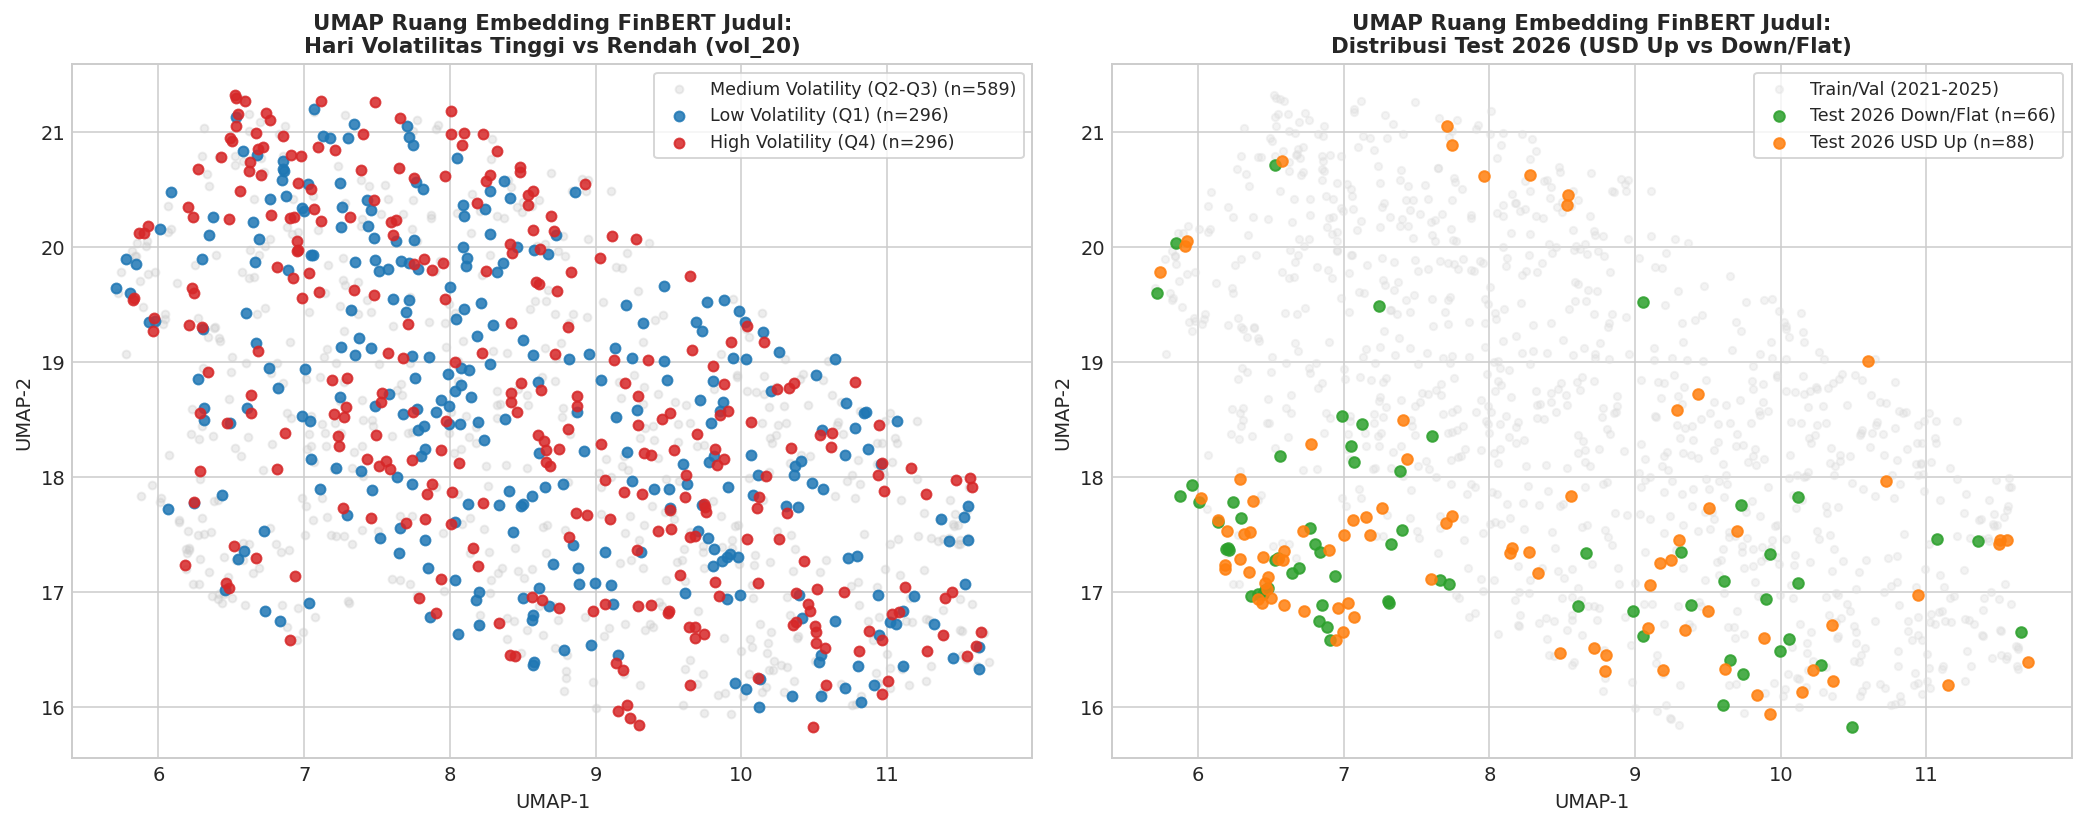

In [10]:
# 5.2 Visualisasi Ruang Embedding UMAP (Volatilitas Pasar Tinggi vs Rendah & Topik)
from umap import UMAP

umap_2d = UMAP(n_neighbors=15, min_dist=0.1, metric='cosine', random_state=RANDOM_SEED, n_jobs=1)
coords = umap_2d.fit_transform(X_fase2_raw768)

vol_series = full_market_df['vol_20'].values
q_low, q_high = np.quantile(vol_series, [0.25, 0.75])
vol_regime = np.where(vol_series >= q_high, 'High Volatility (Q4)',
             np.where(vol_series <= q_low, 'Low Volatility (Q1)', 'Medium Volatility (Q2-Q3)'))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=140)

# Left: High vs Low Volatility
palette_vol = {'High Volatility (Q4)': '#d62728', 'Low Volatility (Q1)': '#1f77b4', 'Medium Volatility (Q2-Q3)': '#cccccc'}
for reg in ['Medium Volatility (Q2-Q3)', 'Low Volatility (Q1)', 'High Volatility (Q4)']:
    m = (vol_regime == reg)
    axes[0].scatter(coords[m, 0], coords[m, 1], c=palette_vol[reg], label=f"{reg} (n={m.sum()})",
                    alpha=0.35 if 'Medium' in reg else 0.85, s=16 if 'Medium' in reg else 26)
axes[0].set_title('UMAP Ruang Embedding FinBERT Judul:\nHari Volatilitas Tinggi vs Rendah (vol_20)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('UMAP-1'); axes[0].set_ylabel('UMAP-2')
axes[0].legend(frameon=True, fontsize=9)

# Right: Test 2026 Market Direction (Up vs Down) + Highlight High Vol
m_test_up = test_mask & (y == 1)
m_test_dn = test_mask & (y == 0)
axes[1].scatter(coords[~test_mask, 0], coords[~test_mask, 1], c='#dddddd', label='Train/Val (2021-2025)', alpha=0.35, s=14)
axes[1].scatter(coords[m_test_dn, 0], coords[m_test_dn, 1], c='#2ca02c', label=f'Test 2026 Down/Flat (n={m_test_dn.sum()})', alpha=0.85, s=30)
axes[1].scatter(coords[m_test_up, 0], coords[m_test_up, 1], c='#ff7f0e', label=f'Test 2026 USD Up (n={m_test_up.sum()})', alpha=0.85, s=30)
axes[1].set_title('UMAP Ruang Embedding FinBERT Judul:\nDistribusi Test 2026 (USD Up vs Down/Flat)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('UMAP-1'); axes[1].set_ylabel('UMAP-2')
axes[1].legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'pipeline5_umap_volatility_topics.png', dpi=150, bbox_inches='tight')
plt.show()


In [11]:
# 5.3 Feature Importance (Permutation Importance pada Model C / Early MLP)
feat_names = list(MARKET_FEATURES)
group_slices = [('Market Technical (8d)', 0, len(MARKET_FEATURES))]
cursor = len(MARKET_FEATURES)

if win_spec['spacy'] == 'struct':
    sp_names = [f'spacy_{k}' for k in ['org','gpe','per','norp','money_pct','geo_other','tot','dens']]
    feat_names += sp_names
    group_slices.append(('spaCy NER Struct (8d)', cursor, cursor + len(sp_names)))
    cursor += len(sp_names)
elif win_spec['spacy'] == 'full':
    sp_names = [f'spacy_{k}' for k in ['org','gpe','per','norp','money_pct','geo_other','tot','dens']] + [f'spacy_svd_{i}' for i in range(16)]
    feat_names += sp_names
    group_slices.append(('spaCy NER Full (24d)', cursor, cursor + len(sp_names)))
    cursor += len(sp_names)

if win_spec['gaz']:
    gaz_names = ['gaz_cb','gaz_fx','gaz_macro','gaz_geo','gaz_em','gaz_cb_rat','gaz_fx_rat','gaz_mac_rat','gaz_geo_rat','gaz_rel_rat']
    feat_names += gaz_names
    group_slices.append(('Gazetteer Makro+FX (10d)', cursor, cursor + len(gaz_names)))
    cursor += len(gaz_names)

if win_spec['finbert'] is not None or win_spec['topic'] is None:
    fb_names = [f'finbert_pc{i+1}' for i in range(X_fase2_pca32.shape[1])]
    feat_names += fb_names
    group_slices.append(('FinBERT Judul (PCA 32d)', cursor, cursor + len(fb_names)))
    cursor += len(fb_names)

if win_spec['topic'] == 'bertopic':
    bt_names = [f'bertopic_{i+1}' for i in range(X_bertopic.shape[1])]
    feat_names += bt_names
    group_slices.append(('BERTopic(FinBERT) (16d)', cursor, cursor + len(bt_names)))
    cursor += len(bt_names)
elif win_spec['topic'] == 'nmf':
    nmf_names = [f'nmf_t{i+1}' for i in range(X_nmf.shape[1])]
    feat_names += nmf_names
    group_slices.append(('NMF Topics (16d)', cursor, cursor + len(nmf_names)))
    cursor += len(nmf_names)

assert len(feat_names) == X_early_locked.shape[1], f"Dim mismatch: {len(feat_names)} vs {X_early_locked.shape[1]}"

# Permutation Importance on X_early_locked Test 2026 using res_early_mlp model+scaler
mlp_mod = res_early_mlp['model']
mlp_sc = res_early_mlp['scaler']
X_te_base = mlp_sc.transform(X_early_locked[test_mask])
base_auc = res_early_mlp['test_metrics']['AUC']

def score_scaled_mlp(X_s):
    mlp_mod.eval()
    with torch.no_grad():
        p = torch.sigmoid(mlp_mod(torch.tensor(X_s, dtype=torch.float32).to(device))).cpu().numpy().flatten()
    return roc_auc_score(y_test, p), accuracy_score(y_test, (p >= 0.5).astype(int)) * 100.0

rng = np.random.default_rng(RANDOM_SEED)
grp_imp = []
for gname, s_idx, e_idx in group_slices:
    auc_drops, acc_drops = [], []
    base_acc = res_early_mlp['test_metrics']['Acc']
    for _ in range(15):
        X_perm = X_te_base.copy()
        perm_order = rng.permutation(len(X_perm))
        X_perm[:, s_idx:e_idx] = X_perm[perm_order, s_idx:e_idx]
        p_auc, p_acc = score_scaled_mlp(X_perm)
        auc_drops.append(base_auc - p_auc)
        acc_drops.append(base_acc - p_acc)
    grp_imp.append({
        'Feature_Group': gname,
        'Dim': e_idx - s_idx,
        'AUC_Drop': round(float(np.mean(auc_drops)), 4),
        'Acc_Drop(%)': round(float(np.mean(acc_drops)), 2),
    })

df_grp_imp = pd.DataFrame(grp_imp).sort_values('AUC_Drop', ascending=False)
print("=== PERMUTATION IMPORTANCE PER GRUP FITUR (TEST 2026) ===")
display(df_grp_imp)

ind_imp = []
for j, fname in enumerate(feat_names):
    drops = []
    for _ in range(10):
        X_perm = X_te_base.copy()
        X_perm[:, j] = X_perm[rng.permutation(len(X_perm)), j]
        p_auc, _ = score_scaled_mlp(X_perm)
        drops.append(base_auc - p_auc)
    ind_imp.append({'Feature': fname, 'AUC_Drop': round(float(np.mean(drops)), 4)})
df_ind_imp = pd.DataFrame(ind_imp).sort_values('AUC_Drop', ascending=False)
print("=== TOP-12 FITUR INDIVIDU BERDASARKAN PERMUTATION AUC DROP (TEST 2026) ===")
display(df_ind_imp.head(12))
print("\n=== SAMPEL TOPIK NMF vs BERTopic(FinBERT) ===")
display(df_topics_meta.groupby('Model').head(5))


=== PERMUTATION IMPORTANCE PER GRUP FITUR (TEST 2026) ===


,Feature_Group,Dim,AUC_Drop,Acc_Drop(%)
2,FinBERT Judul (PCA 32d),32,0.0687,6.41
0,Market Technical (8d),8,0.0231,-0.17
1,spaCy NER Struct (8d),8,0.0051,3.29


=== TOP-12 FITUR INDIVIDU BERDASARKAN PERMUTATION AUC DROP (TEST 2026) ===


,Feature,AUC_Drop
34,finbert_pc19,0.0349
2,ret_3d,0.0346
44,finbert_pc29,0.0345
22,finbert_pc7,0.0180
13,spacy_geo_other,0.0146
9,spacy_gpe,0.0138
15,spacy_dens,0.0134
30,finbert_pc15,0.0129
26,finbert_pc11,0.0124
23,finbert_pc8,0.0114



=== SAMPEL TOPIK NMF vs BERTopic(FinBERT) ===


,Model,Topic_ID,Top_Terms,Count_Train
0,NMF,0,"ukraine, russia, war, ukraine war, putin, russ...",NaN
1,NMF,1,"china, taiwan, xi, tech, covid, beijing, trade...",NaN
2,NMF,2,"cnbc, open, daily, daily open, cnbc daily, ind...",NaN
3,NMF,3,"says, chief, ceo, chief says, ceo says, minist...",NaN
4,NMF,4,"korea, north, north korea, south, south korea,...",NaN
15,BERTopic(FinBERT),0,"gaza, killed, attack, israel, israeli, russian...",705.0
16,BERTopic(FinBERT),1,"russian, court, probe, charges, russia, ukrain...",674.0
17,BERTopic(FinBERT),2,"election, minister, prime minister, prime, par...",528.0
18,BERTopic(FinBERT),3,"economy, warns, global, war, crisis, says, rec...",451.0
19,BERTopic(FinBERT),4,"china, says, trade, ties, nato, membership, re...",324.0


[Error Analysis Test 2026 (n=154)] Summary Counts:
Outcome
BOTH_CORRECT                                 59
BOTH_WRONG                                   50
NLP_SAVED (Model C Benar, Market A Salah)    26
NLP_NOISE (Market A Benar, Model C Salah)    19

=== CONTOH TANGGAL 'NLP_SAVED' (Model C Menyelamatkan Sinyal Palsu Pasar, total 26 hari) ===


,trading_date,y_true,ret_1d_pct,n_articles,prob_A_Market,prob_C_Final,Outcome,Sample_Headlines
121,2026-07-14,0,-0.176,6,0.552,0.184,"NLP_SAVED (Model C Benar, Market A Salah)",Europe's Anduril rival Helsing raises $1.8 bil...
152,2026-08-28,1,-0.332,6,0.455,0.666,"NLP_SAVED (Model C Benar, Market A Salah)",Z.ai shares surge 8% after releasing new AI mo...
90,2026-05-26,1,0.259,5,0.499,0.642,"NLP_SAVED (Model C Benar, Market A Salah)",Huawei plans new smartphone chips this fall as...
18,2026-01-29,1,0.377,13,0.475,0.630,"NLP_SAVED (Model C Benar, Market A Salah)",Ex-Palantir engineer raises $40 million for cy...
1,2026-01-05,1,0.138,21,0.465,0.629,"NLP_SAVED (Model C Benar, Market A Salah)",Behind the mesh curtain: Why airline class war...
78,2026-05-06,0,-0.115,11,0.514,0.382,"NLP_SAVED (Model C Benar, Market A Salah)",UK borrowing costs surge to highest since 1998...
110,2026-06-29,1,-0.590,17,0.455,0.610,"NLP_SAVED (Model C Benar, Market A Salah)",U.S. military attacks Iranian targets after co...
127,2026-07-22,1,0.000,16,0.484,0.605,"NLP_SAVED (Model C Benar, Market A Salah)",Boeing asks U.S. to intervene over record EU l...



=== CONTOH TANGGAL 'NLP_NOISE' (Teks Justru Menambah Noise, total 19 hari) ===


,trading_date,y_true,ret_1d_pct,n_articles,prob_A_Market,prob_C_Final,Outcome,Sample_Headlines
94,2026-06-04,0,0.602,10,0.430,0.631,"NLP_NOISE (Market A Benar, Model C Salah)",France's Macron invites Sam Altman to attend G...
109,2026-06-26,0,0.111,13,0.464,0.613,"NLP_NOISE (Market A Benar, Model C Salah)",Europe’s defense stocks are sliding again. Her...
22,2026-02-04,1,-0.012,10,0.627,0.392,"NLP_NOISE (Market A Benar, Model C Salah)",Ray Dalio warns the world is ‘on the brink’ of...
44,2026-03-10,0,-0.560,18,0.425,0.606,"NLP_NOISE (Market A Benar, Model C Salah)",Prediction markets face questions on Iran war ...
25,2026-02-09,0,-0.290,20,0.499,0.589,"NLP_NOISE (Market A Benar, Model C Salah)",U.S. arrests suspect in 2012 Benghazi consulat...
106,2026-06-23,1,0.275,11,0.528,0.419,"NLP_NOISE (Market A Benar, Model C Salah)",Defense giant KNDS moves closer to IPO after F...
96,2026-06-08,0,0.732,17,0.448,0.576,"NLP_NOISE (Market A Benar, Model C Salah)",Russia's Sechin says U.S. companies benefit fr...
137,2026-08-05,0,-0.554,13,0.459,0.569,"NLP_NOISE (Market A Benar, Model C Salah)",Bessent says U.S. backed Japan’s yen intervent...


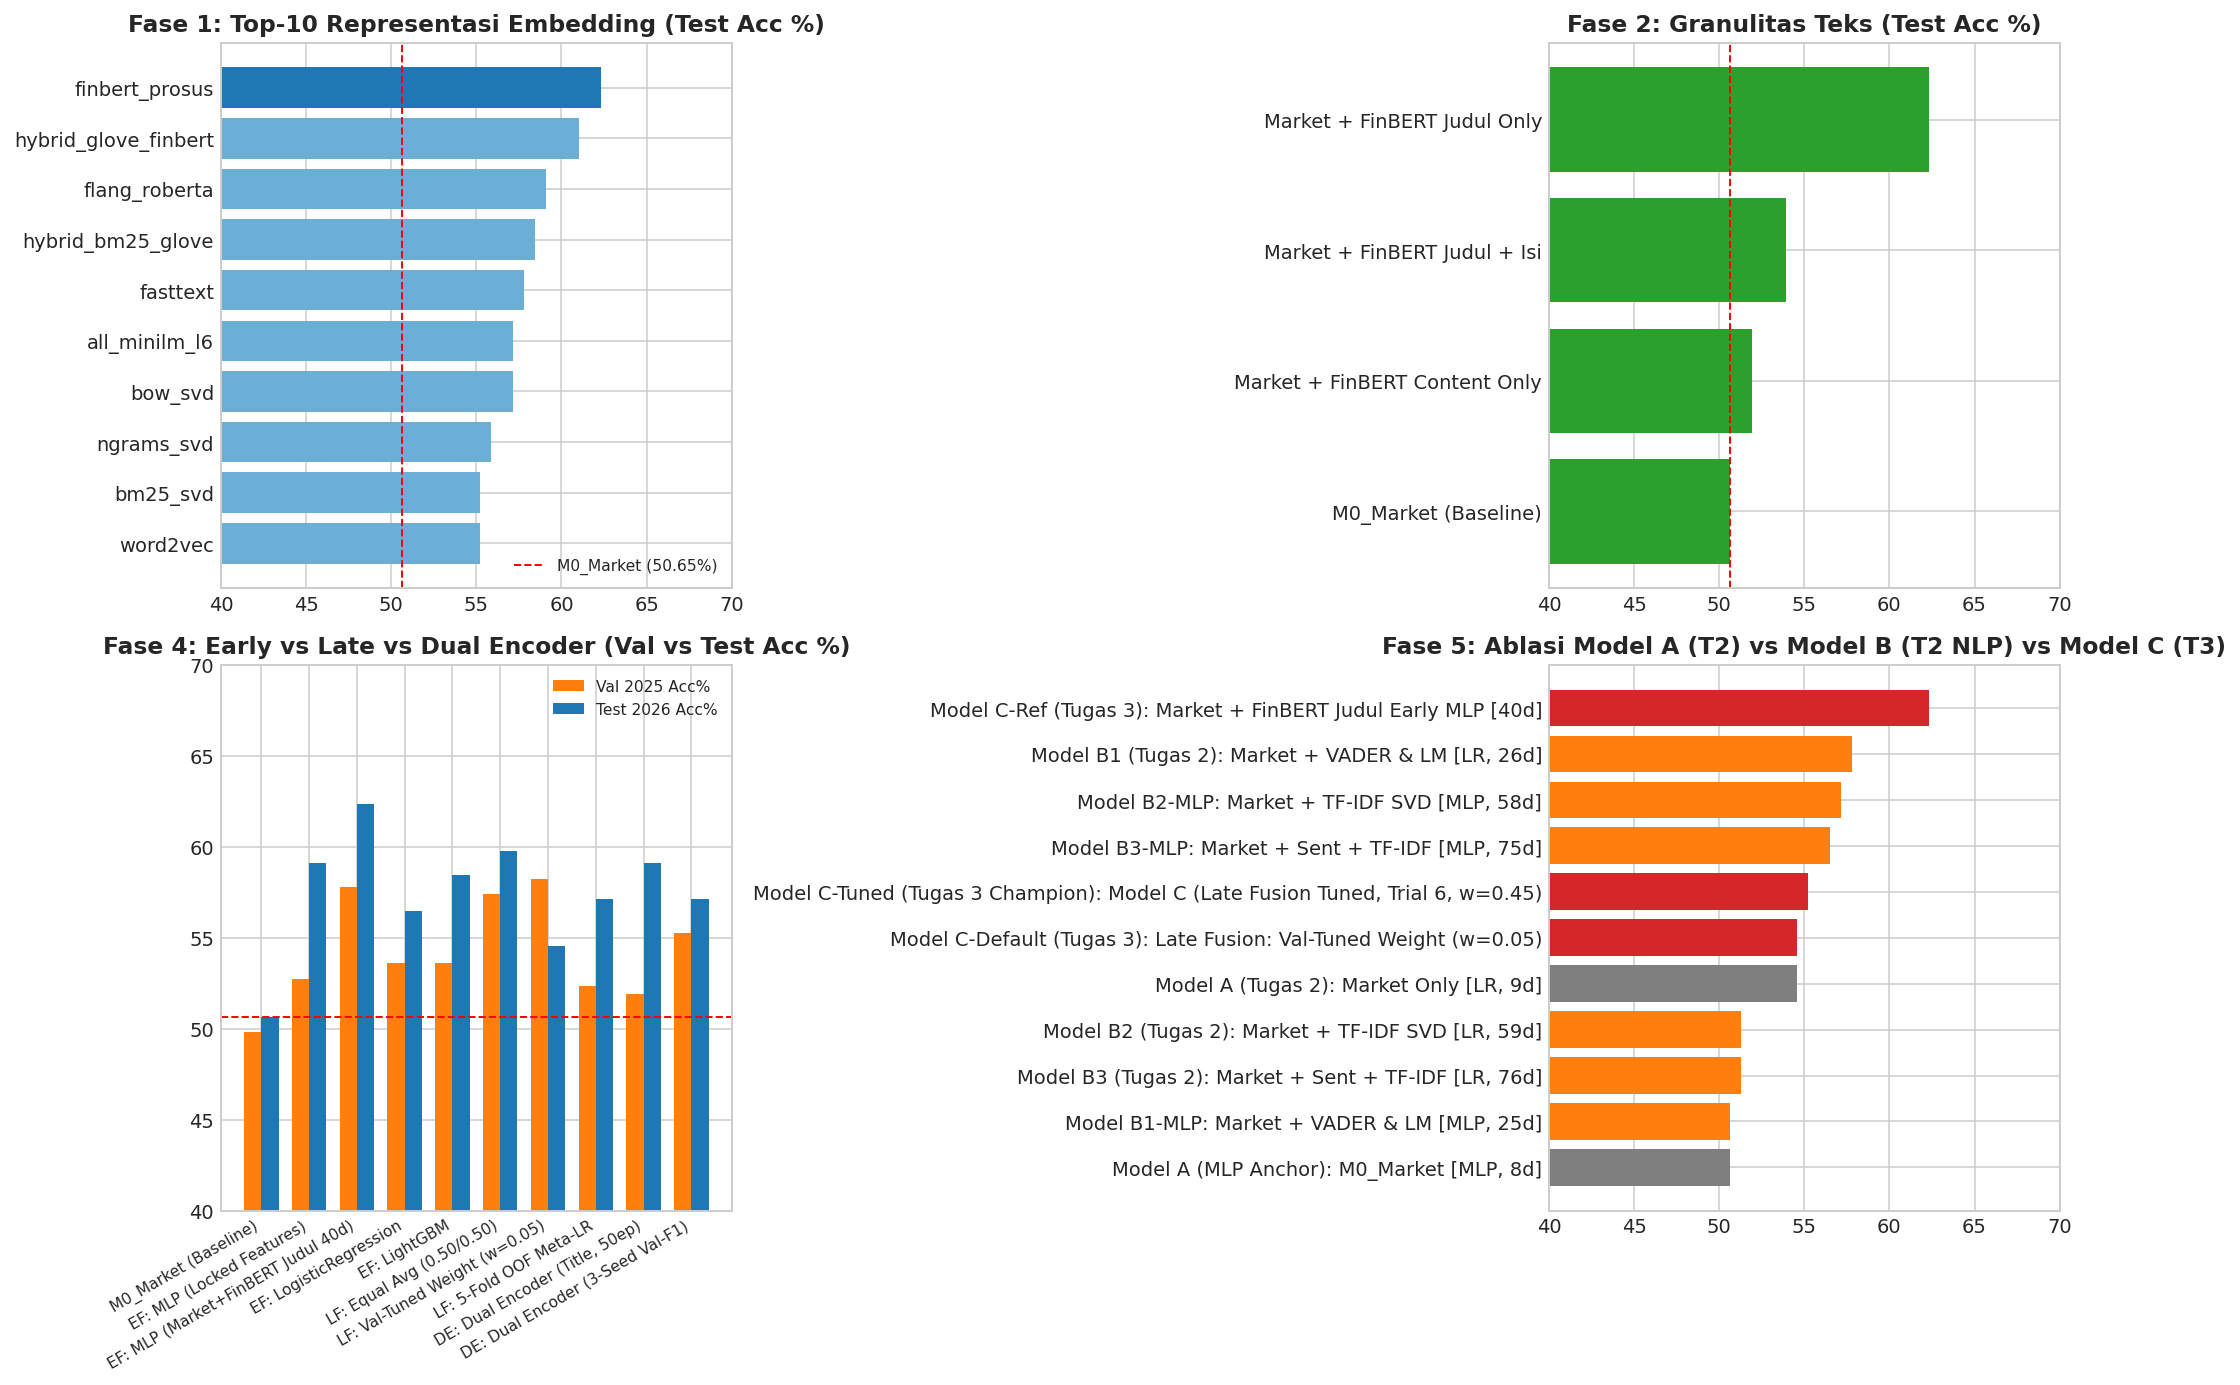

In [12]:
# 5.4 Error Analysis: Tanggal Spesifik NLP Saves (Model C Benar, Model A Salah) vs Text Noise (Model A Benar, Model C Salah)
test_dates = full_market_df.loc[test_mask, 'trading_date'].dt.strftime('%Y-%m-%d').values
test_ret = full_market_df.loc[test_mask, 'ret_1d'].values

# Build daily top headlines lookup
headlines_by_date = merged_news.groupby('effective_trading_date')['title_clean'].apply(
    lambda s: ' | '.join(str(x) for x in list(s)[:2])
).to_dict()
counts_by_date = merged_news.groupby('effective_trading_date').size().to_dict()

preds_A = res_m0['test_preds']
probs_A = res_m0['test_probs']
preds_C = res_model_c_final['test_preds']
probs_C = res_model_c_final['test_probs']

err_rows = []
for i, d in enumerate(test_dates):
    a_ok = int(preds_A[i] == y_test[i])
    c_ok = int(preds_C[i] == y_test[i])
    if c_ok and not a_ok:
        outcome = 'NLP_SAVED (Model C Benar, Market A Salah)'
    elif a_ok and not c_ok:
        outcome = 'NLP_NOISE (Market A Benar, Model C Salah)'
    elif a_ok and c_ok:
        outcome = 'BOTH_CORRECT'
    else:
        outcome = 'BOTH_WRONG'

    err_rows.append({
        'trading_date': d,
        'y_true': int(y_test[i]),
        'ret_1d_pct': round(float(test_ret[i]) * 100.0, 3),
        'n_articles': int(counts_by_date.get(d, 0)),
        'prob_A_Market': round(float(probs_A[i]), 3),
        'prob_C_Final': round(float(probs_C[i]), 3),
        'Outcome': outcome,
        'Sample_Headlines': headlines_by_date.get(d, ''),
    })

df_err = pd.DataFrame(err_rows)
df_err.to_csv(REPORTS_DIR / 'pipeline5_error_analysis_saves_vs_noise.csv', index=False)

saves_df = df_err[df_err['Outcome'].str.startswith('NLP_SAVED')].copy()
noise_df = df_err[df_err['Outcome'].str.startswith('NLP_NOISE')].copy()
print(f"[Error Analysis Test 2026 (n={len(df_err)})] Summary Counts:")
print(df_err['Outcome'].value_counts().to_string())

print(f"\n=== CONTOH TANGGAL 'NLP_SAVED' (Model C Menyelamatkan Sinyal Palsu Pasar, total {len(saves_df)} hari) ===")
saves_df['margin'] = np.abs(saves_df['prob_C_Final'] - 0.5)
display(saves_df.sort_values('margin', ascending=False).drop(columns=['margin']).head(8))

print(f"\n=== CONTOH TANGGAL 'NLP_NOISE' (Teks Justru Menambah Noise, total {len(noise_df)} hari) ===")
noise_df['margin'] = np.abs(noise_df['prob_C_Final'] - 0.5)
display(noise_df.sort_values('margin', ascending=False).drop(columns=['margin']).head(8))

# Plot 4-Panel Summary Visualization across Phases 1-5
fig, axes = plt.subplots(2, 2, figsize=(15, 10), dpi=140)

# Panel 1: Top Fase 1 Embeddings vs M0
top_f1 = df_fase1.sort_values('Test_Acc(%)', ascending=True).tail(10)
colors_f1 = ['#7f7f7f' if 'M0_Market' in m else ('#1f77b4' if m == 'finbert_prosus' else '#6baed6') for m in top_f1['Model']]
axes[0, 0].barh(top_f1['Model'], top_f1['Test_Acc(%)'], color=colors_f1)
axes[0, 0].axvline(m0_test_acc, color='red', linestyle='--', linewidth=1, label=f'M0_Market ({m0_test_acc:.2f}%)')
axes[0, 0].set_title('Fase 1: Top-10 Representasi Embedding (Test Acc %)', fontweight='bold')
axes[0, 0].set_xlim(40, 70); axes[0, 0].legend(fontsize=8)

# Panel 2: Fase 2 Text Granularity
f2_plot = df_fase2[df_fase2['Model'].str.startswith('Market +') | df_fase2['Model'].str.startswith('M0_Market')].sort_values('Test_Acc(%)', ascending=True)
axes[0, 1].barh(f2_plot['Model'], f2_plot['Test_Acc(%)'], color='#2ca02c')
axes[0, 1].axvline(m0_test_acc, color='red', linestyle='--', linewidth=1)
axes[0, 1].set_title('Fase 2: Granulitas Teks (Test Acc %)', fontweight='bold')
axes[0, 1].set_xlim(40, 70)

# Panel 3: Fase 4 Fusion Strategies (Val vs Test)
f4_plot = df_fase4[~df_fase4['Kategori'].str.startswith('Unimodal')].copy()
x_idx = np.arange(len(f4_plot))
w_bar = 0.36
axes[1, 0].bar(x_idx - w_bar/2, f4_plot['Val_Acc(%)'], width=w_bar, label='Val 2025 Acc%', color='#ff7f0e')
axes[1, 0].bar(x_idx + w_bar/2, f4_plot['Test_Acc(%)'], width=w_bar, label='Test 2026 Acc%', color='#1f77b4')
axes[1, 0].axhline(m0_test_acc, color='red', linestyle='--', linewidth=1)
axes[1, 0].set_xticks(x_idx)
axes[1, 0].set_xticklabels([m.replace('Intermediate Fusion: ', 'DE: ').replace('Early Fusion: ', 'EF: ').replace('Late Fusion: ', 'LF: ') for m in f4_plot['Model']], rotation=30, ha='right', fontsize=8)
axes[1, 0].set_ylim(40, 70); axes[1, 0].legend(fontsize=8)
axes[1, 0].set_title('Fase 4: Early vs Late vs Dual Encoder (Val vs Test Acc %)', fontweight='bold')

# Panel 4: Fase 5 Tugas 2 vs Tugas 3 Ablation
f5_plot = df_ablation_final.sort_values('Test_Acc(%)', ascending=True)
cols_f5 = ['#d62728' if 'Tugas 3' in c else ('#ff7f0e' if 'NLP Dasar' in c else '#7f7f7f') for c in f5_plot['Kategori']]
axes[1, 1].barh(f5_plot['Model'], f5_plot['Test_Acc(%)'], color=cols_f5)
axes[1, 1].set_xlim(40, 70)
axes[1, 1].set_title('Fase 5: Ablasi Model A (T2) vs Model B (T2 NLP) vs Model C (T3)', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'pipeline5_fase1_4_progression.png', dpi=150, bbox_inches='tight')
plt.show()
